# Diabetes Knowledge Graph from Vinmec Articles, stored in Neo4j

**Author:** Nguyễn Văn Trường (B23DCCE095) · Intelligent System Development · Graph 01

This notebook walks through the whole project in the order the data flows: why a knowledge graph, where the articles come from, how text becomes facts, how the facts are stored and queried in Neo4j, how the graph looks, and how far it can be trusted. Each step says what was done and, more importantly, why that choice was made over the obvious alternative.

The project is four programs run one after another; each reads the files written by the one before.

```
vinmec.com ─ kg/crawl.py ─▶ dataset/raw/pages/*.json        1,096 articles, split into sections
           ─ kg/extract.py ─▶ dataset/processed/*.csv       entities, facts (subject, relation, object), mentions
           ─ kg/load.py ─▶ Neo4j                            the graph, stored on disk
           ─ Cypher · kg/retriever.py · kg/visualize.py ─▶  answers, retrieved facts, figures
```

They are separate because they fail and change in different ways. Crawling is slow (about 20 minutes) and depends on the network, so it runs once. Extraction is where the rules were tuned again and again, so it has to rerun in seconds without downloading anything. Loading is separate so the database can be wiped and rebuilt from the CSV files at any time. The notebook does not copy this code: it imports it and opens each stage so the data in between can be inspected.

| Part | Content |
|---|---|
| 1 | What a knowledge graph is, built by hand from 7 facts |
| 2 | Data: finding the pages, filtering them, how a page is stored |
| 3 | Extraction: vocabulary, section rules, subject, evidence counting |
| 4 | The resulting graph |
| 5 | Neo4j: data model and loading |
| 6 | Cypher questions: one-hop, two-hop, comparison, symptom checker, path, evidence |
| 7 | Retrieval with `graph_facts()` |
| 8 | Visualisation and entity importance |
| 9 | Quality: precision and the cost of fixing errors |
| 10 | Limitations |

**To run it:** start Neo4j (`docker start neo4j-diabetes`) and load the graph (`python kg/load.py`). Everything from Part 5 on queries the live database. On Windows, set `PYTHONUTF8=1` before starting Jupyter so Vietnamese text is read as UTF-8.

In [1]:
import sys, json, csv, re, random
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "kg"))

RAW = ROOT / "dataset" / "raw"
PROC = ROOT / "dataset" / "processed"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT)

project root: E:\CODING\IS_AI\intelligent_system_assignments\graph_01


## 1. What is a knowledge graph?

### Text is hard to query

Vinmec's disease page for type 2 diabetes contains this passage:

> *"Những triệu chứng kinh điển của tiểu đường: ăn nhiều, uống nhiều, tiểu nhiều, gầy nhiều… Biến chứng mạn tính: nhìn mờ do biến chứng võng mạc… tê bì dị cảm ở bàn chân (biến chứng thần kinh)…"*

A reader understands it at once; a program sees a string of characters. Asked *"which complications of type 2 diabetes affect the eyes?"*, a keyword search can only look for the word "mắt", which may never appear (the text says "võng mạc"), or may appear in a sentence that means something else. And the full answer is usually scattered over several articles worded differently.

### Facts instead of sentences

A knowledge graph keeps knowledge as many small facts, each linking two things through a named relation. Every fact has the same shape, a **triple**: *(subject, relation, object)*. The passage above becomes:

| subject | relation | object |
|---|---|---|
| Đái tháo đường type 2 | HAS_SYMPTOM | Khát nhiều |
| Đái tháo đường type 2 | HAS_SYMPTOM | Tiểu nhiều |
| Đái tháo đường type 2 | HAS_COMPLICATION | Bệnh võng mạc |
| Bệnh võng mạc | AFFECTS_ORGAN | Mắt |

The gain is that a program no longer needs to understand Vietnamese: it only looks for facts with subject "type 2" and relation `HAS_COMPLICATION`. The ambiguity of language is resolved once, when the facts are created, not at every question.

### Why a graph

Draw each thing as a dot (a **node**, or entity, with a type such as `Symptom` or `Drug`) and each fact as an arrow (an **edge**, or relationship) and the facts form a network. Questions then become walks along arrows. "Which organs can type 2 damage?" starts at *type 2*, follows `HAS_COMPLICATION` to the complications, then `AFFECTS_ORGAN` to the organs. No single fact holds the answer; two facts combine into a new one, and the walk itself is the explanation. A neural network that outputs an answer cannot show that.

The next cells build a tiny graph by hand with NetworkX.

8 nodes, 7 edges


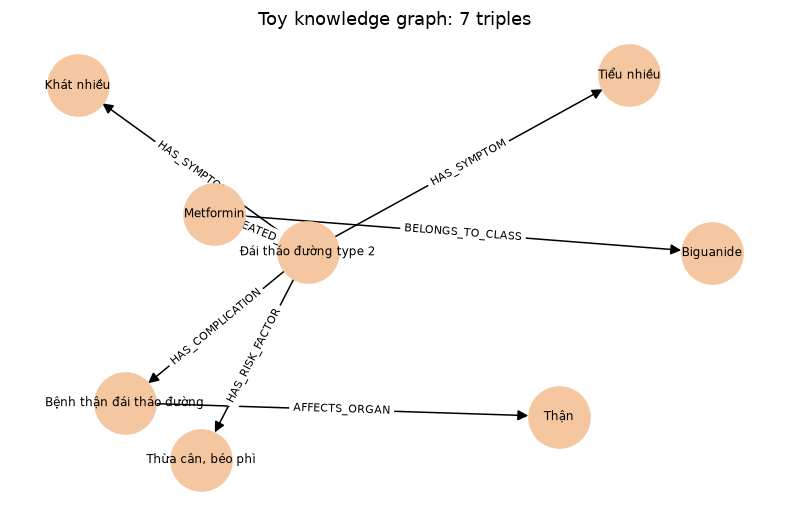

In [2]:
toy = [
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Khát nhiều"),
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Tiểu nhiều"),
    ("Đái tháo đường type 2", "HAS_RISK_FACTOR",  "Thừa cân, béo phì"),
    ("Đái tháo đường type 2", "HAS_COMPLICATION", "Bệnh thận đái tháo đường"),
    ("Đái tháo đường type 2", "TREATED_BY",       "Metformin"),
    ("Bệnh thận đái tháo đường", "AFFECTS_ORGAN", "Thận"),
    ("Metformin", "BELONGS_TO_CLASS", "Biguanide"),
]
T = nx.DiGraph()
for s, r, o in toy:
    T.add_edge(s, o, relation=r)

print(f"{T.number_of_nodes()} nodes, {T.number_of_edges()} edges")
pos = nx.spring_layout(T, seed=3, k=1.4)
plt.figure(figsize=(9, 5.5))
nx.draw_networkx(T, pos, node_color="#f4c7a1", node_size=1600, font_size=8, arrowsize=14)
nx.draw_networkx_edge_labels(T, pos, nx.get_edge_attributes(T, "relation"), font_size=7)
plt.title("Toy knowledge graph: 7 triples"); plt.axis("off"); plt.show()

### One-hop and two-hop questions

A **one-hop** question reads the arrows touching one node. "What do we know about Metformin?" means: find Metformin and list every arrow that enters or leaves it, here *type 2 is treated by Metformin* (arriving) and *Metformin belongs to Biguanide* (leaving). Direction only fixes how a fact is worded, so for "what is known about X" both directions count.

A **two-hop** question chains two arrows through a middle node. No fact says "type 2 damages the kidney". One fact says type 2 can cause diabetic kidney disease, another says that disease affects the kidney; the complication is the bridge. Combining facts is nothing more than following arrows, which is what a list of sentences cannot do.

The helper below turns arrows back into sentences. Part 7 uses the real version of this idea, `graph_facts`, on the real graph.

In [3]:
def toy_facts(G, entity):
    out  = [f"{entity} {d['relation']} {t}." for _, t, d in G.out_edges(entity, data=True)]
    inn  = [f"{s} {d['relation']} {entity}." for s, _, d in G.in_edges(entity, data=True)]
    return out + inn

print("1-hop around Metformin:")
for f in toy_facts(T, "Metformin"): print("  ", f)

print("\n2-hop: organs damaged by type 2")
for _, comp, d1 in T.out_edges("Đái tháo đường type 2", data=True):
    if d1["relation"] != "HAS_COMPLICATION": continue
    for _, organ, d2 in T.out_edges(comp, data=True):
        if d2["relation"] == "AFFECTS_ORGAN":
            print(f"   type 2 → {comp} → {organ}")

1-hop around Metformin:
   Metformin BELONGS_TO_CLASS Biguanide.
   Đái tháo đường type 2 TREATED_BY Metformin.

2-hop: organs damaged by type 2
   type 2 → Bệnh thận đái tháo đường → Thận


Parts 2 to 10 are this same idea at scale. Building a graph from 7 facts takes a minute; the real work is getting **correct facts out of 1,096 Vietnamese articles with no one reading them**, and that is what Parts 2 and 3 are about.

## 2. Data: diabetes articles from Vinmec

### 2.1 Why Vinmec

Vinmec is a large Vietnamese hospital group. Its site publishes thousands of articles written or reviewed by doctors, plus official "disease pages" with a fixed layout (overview, causes, symptoms, risk groups, prevention, diagnosis, treatment). For a Vietnamese diabetes graph it fits: the language is right, the topic is covered in depth (close to a thousand diabetes articles), and the consistent layout is what makes rule-based extraction workable.

### 2.2 Finding the pages

Using the site's search box does not work from a program: the results are drawn by JavaScript in the browser, so downloading the search page returns an empty shell. The crawler reads the **sitemap** instead, the public list of URLs that search engines use. Vinmec's sitemap index points to about 230 sub-sitemaps; the Vietnamese article ones (`posts-vi-*`) and disease ones (`diseases-vi-*`) list roughly 222,000 URLs, the whole Vietnamese site.

To pick diabetes pages out of 222,000 without downloading them all, the crawler looks at the **slug**, the readable tail of the URL, written without accents (`tieu-duong-tuyp-2-…`). A URL is kept when its slug contains a diabetes keyword:

- **strong** keywords (`tieu-duong`, `thao-duong`): almost certainly diabetes;
- **weak** keywords (`insulin`, `hba1c`, `duong-huyet`, `metformin`): might be diabetes, but also appear in articles on the hormone or on blood sugar in healthy people.

`thao-nhat` is excluded on purpose: *đái tháo nhạt* (diabetes insipidus) is a different disease that merely shares two words. This gives **1,197 candidate URLs**, downloaded at one request per second, which the site's `robots.txt` permits.

### 2.3 Why a second filter after downloading

Removing accents from the slug merges words that differ only by accent: `tieu-duong` is *tiểu đường* (diabetes) but also the start of *tiểu dương vật*; `dai-duong` is *đái đường* but also *đại dương* (ocean, as in ocean tuna); `duong` also hides *dưỡng ẩm* (moisturising). Such pages pass the slug filter and are unrelated. So each downloaded page is re-checked on its **accented** text, counting "tiểu đường / đái tháo đường / ĐTĐ" (core mentions) and related terms such as "đường huyết", "insulin", "HbA1c":

- Vinmec's own disease pages are always kept;
- if the title or summary mentions diabetes, 2 core mentions suffice;
- if the slug had a strong keyword, at least 3 core mentions (accent collisions have 0);
- if the slug had only a weak keyword, at least 5 core and 5 related mentions. A page like "Insulin là gì?" can say "insulin" thirty times and diabetes once; that is biology, not the disease.

Thresholds are strict where a wrong page is likely (weak slug) and loose where the title already says what the page is about.

In [4]:
idx = pd.read_csv(RAW / "index.csv")
print(f"candidates checked: {len(idx)}   kept: {idx.relevant.sum()}   rejected: {(~idx.relevant).sum()}")
display(pd.crosstab(idx.slug_match, idx.relevant, margins=True).rename(columns={True: "kept", False: "rejected"}))

print("\nSome rejected pages (accent collisions and off-topic):")
display(idx[~idx.relevant][["title", "slug_match", "core_mentions", "related_mentions"]].dropna().head(8))

candidates checked: 1191   kept: 1096   rejected: 95


relevant,rejected,kept,All
slug_match,,,
strong,10,934,944
weak,85,162,247
All,95,1096,1191



Some rejected pages (accent collisions and off-topic):


,title,slug_match,core_mentions,related_mentions
26,Trẻ 19 tháng đi tiểu dương vật không cử động cần làm gì?,strong,0,0
108,Vô tình hít phải Heroin nên đi thử nước tiểu dương tính có phải không?,strong,0,0
111,Kết quả xét nghiệm nước tiểu dương tính với Amphetamine và Methamphetamine có ý nghĩa gì?,strong,0,0
358,Thành phần dinh dưỡng trong cá ngừ đại dương,strong,2,0
451,Dầu hoa anh thảo dưỡng ẩm da có tốt không?,strong,0,0
784,Bài thuốc từ bí đao chữa bệnh tiểu đường,strong,1,0
942,Hội thảo: Phối hợp đa chuyên khoa trong chăm sóc bệnh nhân đái tháo đường,strong,1,0
945,Chế độ ăn cho trẻ thiếu men glucose 6 và mang gen dương tính với bệnh Thalassemia?,weak,0,6


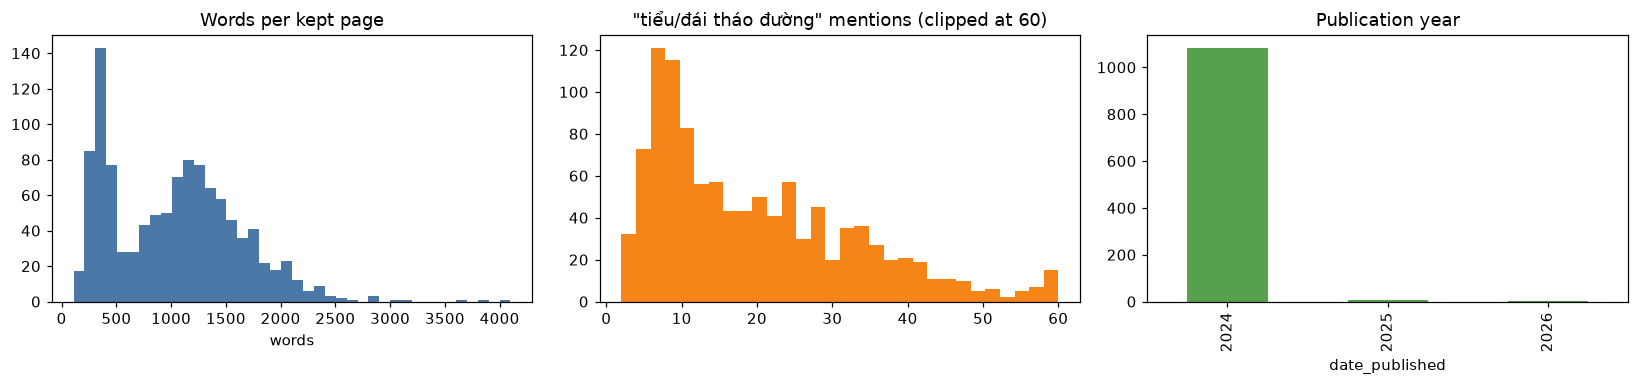

total words in corpus: 1,130,914   median page: 1044 words


In [5]:
kept = idx[idx.relevant]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(kept.n_words, bins=40, color="#4c78a8"); ax[0].set_title("Words per kept page"); ax[0].set_xlabel("words")
ax[1].hist(kept.core_mentions.clip(upper=60), bins=30, color="#f58518"); ax[1].set_title('"tiểu/đái tháo đường" mentions (clipped at 60)')
years = pd.to_datetime(kept.date_published, errors="coerce").dt.year.dropna().astype(int)
years.value_counts().sort_index().plot.bar(ax=ax[2], color="#54a24b"); ax[2].set_title("Publication year")
plt.tight_layout(); plt.show()
print(f"total words in corpus: {kept.n_words.sum():,}   median page: {kept.n_words.median():.0f} words")

### 2.4 How a page is saved

The crawler does not keep raw HTML, where menus, ads, booking forms and scripts outweigh the article about three to one. It extracts the article body and splits it into **sections**, saving for each the **heading**, its **paragraphs** and its **bullets** as separate items.

The heading is the most important thing kept, for a reason Part 3 makes concrete: it says what kind of information the text below it holds. "Mệt mỏi" (fatigue) as a bullet means one thing under "Triệu chứng" and another under "Tác dụng phụ của thuốc". Without the heading the two cannot be told apart.

Trailing boilerplate ("Để đặt lịch khám… HOTLINE…", "Xem thêm:" with links) is cut off. Left in, every article would mention the same booking phrases and the "see also" links would pull in words from unrelated topics.

Below is the type 2 disease page as saved: the section headings and the first bullets of each.

In [6]:
page = json.loads((RAW / "pages" / "tieu-duong-tuyp-2-3042.json").read_text())
print("title:", page["title"]); print("url:  ", page["url"]); print("type: ", page["page_type"], "\n")
for s in page["sections"]:
    print(f"## {s['heading']}   ({len(s['paragraphs'])} paragraphs, {len(s['bullets'])} bullets)")
    for b in s["bullets"][:4]:
        print("     •", b[:110])

title: Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị
url:   https://www.vinmec.com/vie/benh/tieu-duong-tuyp-2-3042
type:  disease 

## Tổng quan bệnh Tiểu đường tuýp 2   (4 paragraphs, 0 bullets)
## Nguyên nhân bệnh Tiểu đường tuýp 2   (1 paragraphs, 0 bullets)
## Triệu chứng bệnh Tiểu đường tuýp 2   (3 paragraphs, 4 bullets)
     • Ăn nhiều
     • Uống nhiều (hay khát nước)
     • Tiểu nhiều (do đường trong nước tiểu cao, gây lợi niệu thẩm thấu)
     • Gầy nhiều (gầy sút cân): bệnh nhân tiểu đường tuýp 2 thường có thể trạng béo, nhưng khi có triệu chứng tăng đư
## Biến chứng cấp tính   (1 paragraphs, 0 bullets)
## Biến chứng mạn tính   (0 paragraphs, 6 bullets)
     • Nhìn mờ (do biến chứng võng mạc, đục thủy tinh thể)
     • Đau ngực thường không điển hình (do biến chứng mạch vành)
     • Tê bì dị cảm ở bàn chân (biến chứng thần kinh)
     • Loét, nhiễm trùng bàn chân
## Đối tượng nguy cơ bệnh Tiểu đường tuýp 2   (0 paragraphs, 8 bullets)
     • Béo phì: tình trạ

## 3. Extraction: from text to facts

This is `kg/extract.py`: read 1,096 articles and output (subject, relation, object) facts with no human in the loop.

### Why not make every bullet a node?

The tempting shortcut is to turn each bullet under "Triệu chứng" into a Symptom node. On the type 2 page that yields clean nodes such as "Ăn nhiều". But a bullet under "điều trị" on the type 1 page reads:

> *"Kiểm soát đường huyết: đối với tuýp 1 thì kiểm soát bằng insulin ngoại sinh là chủ yếu. Dùng theo phác đồ, tuân thủ giờ tiêm và liều lượng tránh bị tụt đường huyết. Các loại insulin gồm có…"*

Sixty words as a node is useless: no other page repeats them, so it never connects to anything. Even short bullets vary ("uống nhiều", "khát nước", "hay khát"), so "diabetes causes thirst" would fall into three fragments that never meet.

So the design decides **in advance** what the graph may contain, gives each thing one clean name, and searches the text for every way of writing it. That fixed list is the **vocabulary**.

### The three questions asked of every section

1. **Which diabetes is the page about?** This is the subject (type 1, type 2, gestational, prediabetes, or diabetes in general).
2. **What may this section contain?** The heading decides: symptoms under "Triệu chứng", drugs under "Điều trị".
3. **Which vocabulary entries appear in the section?** These are the objects.

Each fact found on a page is a **vote** from that page; a fact enters the graph only if enough different pages voted for it.

### 3.1 The vocabulary (`kg/vocab.py`)

An entry has a canonical **name** (the node), a **type**, and **aliases**, the ways articles actually write it:

| name | type | aliases searched |
|---|---|---|
| Khát nhiều | Symptom | khát nhiều, uống nhiều, khát nước, hay khát, khô miệng |
| Metformin | Drug | metformin, glucophage (brand) |
| Bệnh võng mạc | Complication | võng mạc, biến chứng mắt, mù lòa |

Mapping many spellings to one node is **entity normalisation**, and it is what lets evidence add up: "uống nhiều" in one article and "khát nước" in another both vote for *(diabetes, HAS_SYMPTOM, Khát nhiều)*.

The list was written by hand from what the articles discuss: classic symptoms, the risk factors on Vinmec's pages, acute and chronic complications, standard tests, drugs used in Vietnam (with brand names like Diamicron, Januvia, Jardiance), foods and lifestyle advice. The cost is plain, anything off the list is invisible, and so is the benefit, every node is clean. Part 10 returns to the cost.

In [7]:
import vocab
from extract import PATTERNS, LABEL, subject_of, allowed_labels, about_disease, matches

v = pd.DataFrame([(n, lab, len(al), ", ".join(al[:5])) for n, (lab, al) in vocab.VOCAB.items()],
                 columns=["entity", "type", "n_aliases", "first aliases"])
print(f"{len(v)} vocabulary entities, {v.n_aliases.sum()} aliases")
display(v.groupby("type").agg(entities=("entity", "count"), aliases=("n_aliases", "sum")).sort_values("entities", ascending=False))
display(v.sample(8, random_state=1))

106 vocabulary entities, 320 aliases


,entities,aliases
type,,
Drug,22,42
Complication,19,52
RiskFactor,17,52
Food,16,66
Symptom,16,56
Test,10,35
Lifestyle,6,17


,entity,type,n_aliases,first aliases
66,Insulin lispro,Drug,2,"lispro, humalog"
35,Tăng áp lực thẩm thấu,Complication,2,"tăng áp lực thẩm thấu, tăng áp lực thẩm thấu máu"
59,Máy đo đường huyết,Test,4,"máy đo đường huyết, tự theo dõi đường huyết, đo đường huyết tại nhà, cgm"
77,Canagliflozin,Drug,1,canagliflozin
39,Tăng nhãn áp,Complication,3,"tăng nhãn áp, glaucoma, cườm nước"
56,Xét nghiệm nước tiểu,Test,4,"xét nghiệm nước tiểu, tổng phân tích nước tiểu, đường niệu, ceton niệu"
55,Đường huyết ngẫu nhiên,Test,3,"đường huyết bất kỳ, đường huyết bất kì, đường huyết ngẫu nhiên"
87,Cá béo,Food,5,"cá hồi, cá thu, cá béo, omega-3, omega 3"


### 3.2 Finding an alias in text

All aliases of an entry are compiled into one regular expression. Three details matter.

**Whole words only.** Vietnamese separates syllables with spaces, so many aliases are one short syllable that also sits inside longer words: "lê" (pear) inside "lên" (as in "lên cân"), "bia" (beer) inside "biên". The pattern requires a non-letter on both sides; the demo shows "lên cân" matching nothing and "quả lê" matching the fruit.

**Longest alias first.** "Tiểu nhiều" has "đi tiểu thường xuyên" and the shorter "tiểu thường xuyên". Trying the short one first would shadow the precise one.

**Lower-case but keep accents.** Case is folded ("HbA1C" = "hba1c") but accents never are; dropping them would recreate the URL problem of 2.3, with *tiểu đường* equal to *tiểu dương*.

**What remains unsolved.** "táo" (apple) is a whole word inside "táo bón" (constipation), so boundaries cannot stop it; the last demo line shows the false match. What limits the damage is the section rule below, since a food alias counts only in diet sections where constipation rarely appears. The problem is reduced, not removed, and is listed in Part 10.

The cell applies the matcher to a real sentence from the type 1 page.

In [ ]:
# Khớp nguyên từ, thử alias dài trước, giữ dấu.
sentence = "Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều."
print(sentence, "\n")
for lab in ["Test", "Symptom", "Drug"]:
    print(f"{lab:8s} →", matches(sentence, {lab}))

print("\nWord boundary demo:")
for text in ["bệnh nhân lên cân", "ăn quả lê", "uống bia", "bị táo bón kéo dài"]:
    print(f"  {text!r:22} Food matches → {matches(text, {'Food'})}")

Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều. 

Test     → ['HbA1c', 'Đường huyết lúc đói']
Symptom  → ['Khát nhiều', 'Tiểu nhiều']
Drug     → []

Word boundary demo:
  'bệnh nhân lên cân'    Food matches → []
  'ăn quả lê'            Food matches → ['Trái cây ít ngọt']
  'uống bia'             Food matches → ['Rượu bia']
  'bị táo bón kéo dài'   Food matches → ['Trái cây ít ngọt']


### 3.3 The section rule: the heading decides

Finding a vocabulary word in an article does not mean the article states a fact about it. From the corpus:

- "mệt mỏi" appears in a diet article ("ăn sáng đầy đủ giúp bạn đỡ mệt mỏi"): not a symptom claim;
- "tăng huyết áp" appears in drug paragraphs as a condition to avoid combining with;
- nearly every article says "insulin" while explaining blood sugar, not because insulin is the treatment under discussion.

Accepting every match would give diabetes dozens of "symptoms" that are just words that happened to occur. So a match counts only when the **heading** says the section is about that kind of information. That works because hospital articles are organised by exactly these headings.

| heading contains | extract | relation |
|---|---|---|
| triệu chứng, dấu hiệu, biểu hiện, nhận biết | symptoms | HAS_SYMPTOM |
| nguyên nhân, nguy cơ, đối tượng, yếu tố, ai dễ | risk factors | HAS_RISK_FACTOR |
| biến chứng, nguy hiểm, hậu quả, ảnh hưởng | complications | HAS_COMPLICATION |
| chẩn đoán, xét nghiệm, chỉ số, kiểm tra, theo dõi | tests | DIAGNOSED_BY |
| điều trị, thuốc, insulin, kiểm soát | drugs, lifestyle | TREATED_BY, MANAGED_BY |
| phòng ngừa, lối sống, lưu ý | lifestyle | MANAGED_BY |
| ăn, thực phẩm, dinh dưỡng, thực đơn, kiêng | foods | RECOMMENDS_FOOD / AVOIDS_FOOD |

A heading with none of these words (e.g. "Tổng quan") yields nothing: overviews mention everything in passing, and missing a fact is better than inventing one.

**A second check for symptoms and risk factors.** The quality audit in Part 9 exposed a gap in the first version. A heading can contain "nguyên nhân" or "nguy cơ" and still not be about diabetes:

- *"Một số nguyên nhân gây ngứa bàn tay và bàn chân"* lists causes of **itching**;
- *"Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường"* lists risks of **stroke** in people who already have diabetes;
- *"Làm gì để giảm thiểu nguy cơ tim mạch…"* is advice on **lowering** a risk.

Reading those bullets as risk factors *of diabetes* produced false facts such as "high cholesterol is a risk factor of diabetes" when the article meant a kidney complication. A symptom or risk factor always belongs to *something*, and the heading names it. So for these two types `about_disease()` additionally requires that the heading (a) names diabetes or is short and generic ("Triệu chứng", "Ai dễ bị?"), (b) names no other topic (biến chứng, thận, mắt, thần kinh, tim mạch, ngứa, tai biến, hôn mê…), and (c) is not about reducing risk.

The table shows real headings and the decision for each.

In [9]:
headings = [
    "Triệu chứng bệnh Tiểu đường tuýp 2",
    "Đối tượng nguy cơ bệnh Tiểu đường tuýp 1",
    "3. Ai dễ bị tiền tiểu đường?",
    "Các biện pháp điều trị bệnh Tiểu đường tuýp 1",
    "2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh",
    "3. Một số nguyên nhân gây ngứa bàn tay và bàn chân",
    "2. Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường",
    "4. Làm gì để giảm thiểu nguy cơ tim mạch ở bệnh nhân tiểu đường?",
    "Biến chứng mạn tính",
]
display(pd.DataFrame([(h, about_disease(h), sorted(allowed_labels(h))) for h in headings],
                     columns=["section heading", "about diabetes itself?", "allowed entity types"]))

,section heading,about diabetes itself?,allowed entity types
0,Triệu chứng bệnh Tiểu đường tuýp 2,True,[Symptom]
1,Đối tượng nguy cơ bệnh Tiểu đường tuýp 1,True,[RiskFactor]
2,3. Ai dễ bị tiền tiểu đường?,True,[RiskFactor]
3,Các biện pháp điều trị bệnh Tiểu đường tuýp 1,True,"[Drug, Lifestyle]"
4,2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh,True,[Food]
5,3. Một số nguyên nhân gây ngứa bàn tay và bàn chân,False,[]
6,2. Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường,False,[]
7,4. Làm gì để giảm thiểu nguy cơ tim mạch ở bệnh nhân tiểu đường?,False,[]
8,Biến chứng mạn tính,False,[Complication]


### 3.4 Which diabetes is the subject?

Diabetes is not one disease. Type 1 is autoimmune destruction of insulin-producing cells, typically starting young; type 2 develops slowly with weight and lifestyle; gestational diabetes appears in pregnancy; prediabetes precedes type 2. Their symptoms, causes and treatments overlap but differ ("autoimmune destruction of beta cells" is a type 1 cause only; pre-eclampsia belongs to gestational diabetes). One shared "diabetes" node would erase that.

The subject is taken from the page **title**, the author's own statement of the topic and far more reliable than word counts in the body (a type 2 article often mentions type 1 for comparison). The first matching rule wins:

| title contains | subject |
|---|---|
| tuýp 1 / type 1 / típ 1 | Đái tháo đường type 1 |
| tuýp 2 / type 2 / típ 2 | Đái tháo đường type 2 |
| thai kỳ / mang thai / mẹ bầu | Đái tháo đường thai kỳ |
| tiền đái tháo đường / tiền tiểu đường | Tiền đái tháo đường |
| none of these | Đái tháo đường (general) |

The consequence is visible in the chart: most titles name no type ("12 lời khuyên về lối sống để tránh biến chứng tiểu đường"), so the general node gets most facts although many pages are really about type 2. The choice is deliberate. A type 2 fact on the general node is incomplete; on the type 1 node it would be false.

Đái tháo đường type 2     ← Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị
Đái tháo đường thai kỳ    ← Chế độ ăn cho người bị tiểu đường thai kỳ
Tiền đái tháo đường       ← Nguyên nhân và đối tượng nguy cơ tiền tiểu đường
Đái tháo đường            ← 12 lời khuyên về lối sống để tránh biến chứng tiểu đường



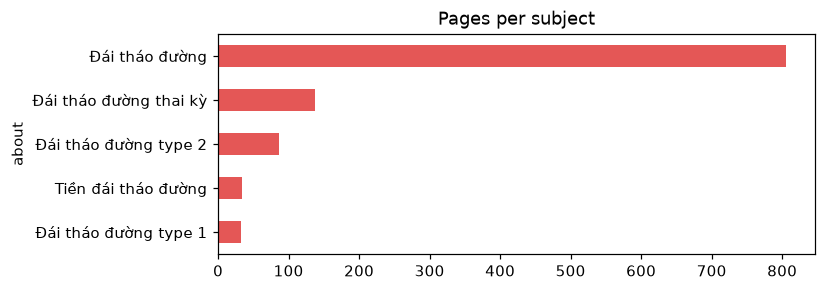

In [10]:
arts = pd.read_csv(PROC / "articles.csv")
for t in ["Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị",
          "Chế độ ăn cho người bị tiểu đường thai kỳ",
          "Nguyên nhân và đối tượng nguy cơ tiền tiểu đường",
          "12 lời khuyên về lối sống để tránh biến chứng tiểu đường"]:
    print(f"{subject_of(t):25s} ← {t}")

print()
arts.about.value_counts().plot.barh(figsize=(7, 2.6), color="#e45756", title="Pages per subject")
plt.gca().invert_yaxis(); plt.show()

### 3.5 One page, end to end

The cell below applies the three questions to the type 2 disease page and prints, per section, what is allowed and which facts the page votes for. Note that:

- "Tổng quan" produces nothing (no keyword in its heading);
- the symptom section yields exactly the four classic symptoms on the page;
- the treatment section yields both drugs and lifestyle measures, since "điều trị" permits both.

In [11]:
subj = subject_of(page["title"])
print("subject:", subj, "\n")
for s in page["sections"]:
    labels = allowed_labels(s["heading"])
    found = sorted({e for unit in s["paragraphs"] + s["bullets"] for e in matches(unit, labels)})
    print(f"## {s['heading']}\n   allowed: {sorted(labels) or '—'}")
    for e in found:
        rel = vocab.RELATION_BY_LABEL.get(LABEL[e], "FOOD")
        print(f"   → ({subj}, {rel}, {e})")

subject: Đái tháo đường type 2 

## Tổng quan bệnh Tiểu đường tuýp 2
   allowed: —
## Nguyên nhân bệnh Tiểu đường tuýp 2
   allowed: ['RiskFactor']
   → (Đái tháo đường type 2, HAS_RISK_FACTOR, Di truyền / tiền sử gia đình)
## Triệu chứng bệnh Tiểu đường tuýp 2
   allowed: ['Symptom']
   → (Đái tháo đường type 2, HAS_SYMPTOM, Khát nhiều)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Sụt cân)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Tiểu nhiều)
   → (Đái tháo đường type 2, HAS_SYMPTOM, Ăn nhiều)
## Biến chứng cấp tính
   allowed: ['Complication']
   → (Đái tháo đường type 2, HAS_COMPLICATION, Nhiễm toan ceton)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Tăng áp lực thẩm thấu)
## Biến chứng mạn tính
   allowed: ['Complication']
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bàn chân đái tháo đường)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bệnh thần kinh ngoại biên)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Bệnh võng mạc)
   → (Đái tháo đường type 2, HAS_COMPLICATION, Liệt dạ d

### 3.6 Counting evidence

Even with these rules a single page can mislead: an unusual heading, a symptom mentioned in passing, a list of things to compare. Trusting every page would put every such slip into the graph.

The defence is **agreement between independent pages**. For each fact the extractor keeps the *set* of pages that voted for it, so a page that says "khát nhiều" five times still counts once; the number of distinct articles is the fact's **support**. A fact is kept when at least **2** pages support it, the same logic as checking a claim against a second source.

Two exceptions, each justified:

- a fact from one of Vinmec's **disease pages** is kept at support 1: they are short, structured and hospital-reviewed, so extraction from them is the most reliable;
- **side effects** need **3** pages, because they come from single sentences (3.8) and are noisier than section-based facts.

Worked example, three pages about type 2:

| page | votes |
|---|---|
| A | Khát nhiều, Mệt mỏi |
| B | Khát nhiều |
| C | Khát nhiều, Run tay |

"Khát nhiều" has support 3 and stays; "Mệt mỏi" and "Run tay" have support 1 and are dropped. The support number is stored on the relationship in Neo4j, so queries can later rank answers by how well documented they are or require, say, at least 5 articles.

In [12]:
votes = {"A": [("type 2","HAS_SYMPTOM","Khát nhiều"), ("type 2","HAS_SYMPTOM","Mệt mỏi")],
         "B": [("type 2","HAS_SYMPTOM","Khát nhiều")],
         "C": [("type 2","HAS_SYMPTOM","Khát nhiều"), ("type 2","HAS_SYMPTOM","Run tay")]}
support = defaultdict(set)
for pg, triples in votes.items():
    for t in triples: support[t].add(pg)
for t, pages in support.items():
    print(f"{t[2]:12s} support={len(pages)}  pages={sorted(pages)}  {'kept' if len(pages) >= 2 else 'dropped'}")

Khát nhiều   support=3  pages=['A', 'B', 'C']  kept
Mệt mỏi      support=1  pages=['A']  dropped
Run tay      support=1  pages=['C']  dropped


### 3.7 Foods: recommended or avoided?

The graph has `RECOMMENDS_FOOD` and `AVOIDS_FOOD`. The first attempt chose between them from cue words in the sentence or heading ("nên ăn" vs "kiêng", "tránh", "hạn chế", "không nên"). It failed because diet writing mixes both in one place: the heading *"Thực phẩm mẹ bầu cần tránh và nên ăn"* contains both cues, and one sentence may say "hạn chế đồ ngọt, thay vào đó nên ăn rau xanh". The output included absurdities like "gestational diabetes AVOIDS green vegetables".

The final rule treats good or bad for diabetes as a **property of the food**, recorded once in the vocabulary: sweets, soft drinks, white rice and refined starch, very sweet fruit (durian, ripe mango, longan, jackfruit), alcohol, fried food and processed meat are "avoid"; the others "recommended". The text only shows that the food is **discussed in a diet section** for that type. This matches standard nutrition advice in nearly all cases; what it cannot express is nuance such as "fruit is fine in moderation".

### 3.8 Drug side effects

Side effects ignore the section rule because they occur anywhere, so they are read **within one sentence**. A sentence yields a fact only if it holds a drug, a symptom or complication, and a causal cue: *"tác dụng phụ"*, *"tác dụng không mong muốn"* or *"gây"*:

> "Insulin có thể **gây hạ đường huyết** nếu tiêm quá liều" → Insulin HAS_SIDE_EFFECT Hạ đường huyết

Sentences containing *"thiếu"* (lack of) or *"không đủ"* are skipped: *"thiếu insulin gây nhiễm toan ceton"* contains a drug, a complication and "gây", yet it says that **lacking** insulin causes ketoacidosis, the reverse of a side effect. Without the exception the graph would blame insulin for the condition it treats.

### 3.9 Background facts added by hand

Some knowledge is not "stated" in any section; it is classification every clinician takes for granted and the articles assume. These facts are added by hand and labelled `source = "curated"`, so they can always be told from extracted ones:

- each drug and its **class** (Metformin → Biguanide, Empagliflozin → SGLT2 inhibitor …);
- each complication and the **organ** it affects (retinopathy → eye, nephropathy → kidney …);
- each diabetes type as a **subtype** of diabetes in general;
- diagnostic **thresholds** stored on the test nodes, from the Vietnamese Ministry of Health 2020 guideline and the ADA criteria that Vinmec's pages also quote.

These few facts unlock the most interesting questions. Without "retinopathy affects the eye" the graph knows type 2 causes retinopathy but cannot answer "which organs does type 2 damage?".

In [13]:
print("Side-effect rule on three sentences:\n")
for s in ["Insulin có thể gây hạ đường huyết nếu tiêm quá liều.",
          "Thiếu insulin gây nhiễm toan ceton.",
          "Metformin là thuốc đầu tay cho tiểu đường tuýp 2."]:
    low = s.lower()
    cue = any(c in low for c in ["tác dụng phụ", "tác dụng không mong muốn", " gây "])
    cause = "thiếu" in low or "không đủ" in low
    drugs, eff = matches(s, {"Drug"}), matches(s, {"Symptom", "Complication"})
    verdict = [(d, "HAS_SIDE_EFFECT", e) for d in drugs for e in eff] if cue and not cause else "no triple"
    print(f"  {s}\n     cue={cue} cause-sentence={cause} drugs={drugs} effects={eff} → {verdict}\n")

Side-effect rule on three sentences:

  Insulin có thể gây hạ đường huyết nếu tiêm quá liều.
     cue=True cause-sentence=False drugs=['Insulin'] effects=['Hạ đường huyết'] → [('Insulin', 'HAS_SIDE_EFFECT', 'Hạ đường huyết')]

  Thiếu insulin gây nhiễm toan ceton.
     cue=True cause-sentence=True drugs=['Insulin'] effects=['Nhiễm toan ceton'] → no triple

  Metformin là thuốc đầu tay cho tiểu đường tuýp 2.
     cue=False cause-sentence=False drugs=['Metformin'] effects=[] → no triple



## 4. The resulting graph

`extract.py` writes four CSV files:

| file | one row is | purpose |
|---|---|---|
| `entities.csv` | an entity: name, type, (tests) threshold | becomes nodes |
| `triples.csv` | a fact: subject, relation, object, support, source, ≤ 5 example URLs | becomes relationships |
| `articles.csv` | a crawled page: URL, title, subject | traces facts back to articles |
| `mentions.csv` | (page, entity) for every entity mentioned anywhere on the page | looser signal of what each page discusses |

`triples.csv` uses the lecture's `subject, relation, object` format plus three columns: `support` (pages backing the fact), `source` (`vinmec` or `curated`) and `example_urls`. The URLs make the graph explainable: for any fact, the original article can be opened and the sentence read.

In [14]:
ent = pd.read_csv(PROC / "entities.csv")
tri = pd.read_csv(PROC / "triples.csv")
print(f"entities: {len(ent)}   triples: {len(tri)}   relation types: {tri.relation.nunique()}   entity types: {ent.label.nunique()}")
print(f"extracted from text: {(tri.source == 'vinmec').sum()}   curated: {(tri.source == 'curated').sum()}")
display(tri[tri.source == "vinmec"].sort_values("support", ascending=False).head(12)[["subject", "relation", "object", "support"]])

entities: 127   triples: 339   relation types: 12   entity types: 10
extracted from text: 301   curated: 38


,subject,relation,object,support
295,Đái tháo đường,TREATED_BY,Insulin,143
239,Đái tháo đường,MANAGED_BY,Tập thể dục đều đặn,114
240,Đái tháo đường,MANAGED_BY,Giảm cân,75
96,Đái tháo đường,HAS_COMPLICATION,Bệnh tim mạch,56
259,Đái tháo đường,RECOMMENDS_FOOD,Ngũ cốc nguyên hạt,54
16,Đái tháo đường,AVOIDS_FOOD,Rượu bia,48
97,Đái tháo đường,HAS_COMPLICATION,Bệnh thần kinh ngoại biên,44
17,Đái tháo đường,AVOIDS_FOOD,"Đồ ngọt, bánh kẹo",44
260,Đái tháo đường,RECOMMENDS_FOOD,Trái cây ít ngọt,44
261,Đái tháo đường,RECOMMENDS_FOOD,Rau xanh,43


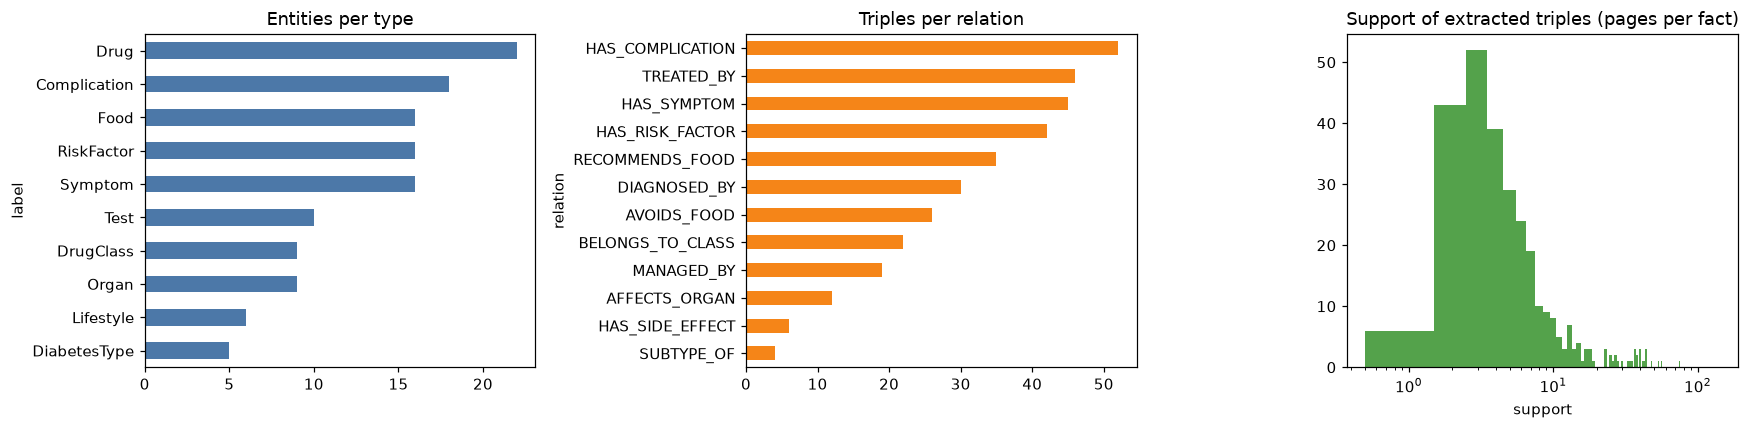

support quantiles: {0.25: 3.0, 0.5: 5.0, 0.75: 9.0, 0.9: 23.0}


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ent.label.value_counts().plot.barh(ax=ax[0], color="#4c78a8", title="Entities per type"); ax[0].invert_yaxis()
tri.relation.value_counts().plot.barh(ax=ax[1], color="#f58518", title="Triples per relation"); ax[1].invert_yaxis()
ext = tri[tri.source == "vinmec"]
ax[2].hist(ext.support, bins=np.arange(1, ext.support.max() + 2) - 0.5, color="#54a24b")
ax[2].set_xscale("log"); ax[2].set_title("Support of extracted triples (pages per fact)"); ax[2].set_xlabel("support")
plt.tight_layout(); plt.show()
print("support quantiles:", ext.support.quantile([.25, .5, .75, .9]).to_dict())

### Reading the charts

Drugs, complications, risk factors, symptoms and foods each have 16 to 22 entities, close to the vocabulary size per type, so nearly every vocabulary entry found enough support in the articles.

The support histogram says more. The typical fact is backed by 5 pages, while a few are repeated by dozens: "diabetes is treated with insulin" by 143, "managed by regular exercise" by 114. That is typical of a health site: the core message (exercise, diet, insulin, the main complications) is in nearly every article, while specific facts such as a newer drug's class appear once or twice. Support therefore also measures how central a fact is to how Vinmec talks about diabetes.

### 4.1 Do the types really differ?

If giving each type its own subject (3.4) works, the types should show different facts. The heatmaps show, per complication and type, the number of supporting pages (darker = more, blank = no fact).

Two things stand out. The general column is darkest by far, the consequence of 3.4. And gestational diabetes has its own pattern: hypoglycaemia (mother on treatment, newborn), pre-eclampsia, premature birth and an oversized baby, all pregnancy complications, whereas type 1 and type 2 share the long-term eye, kidney, nerve and heart complications. That is medically right, which suggests the subject rule captures real differences.

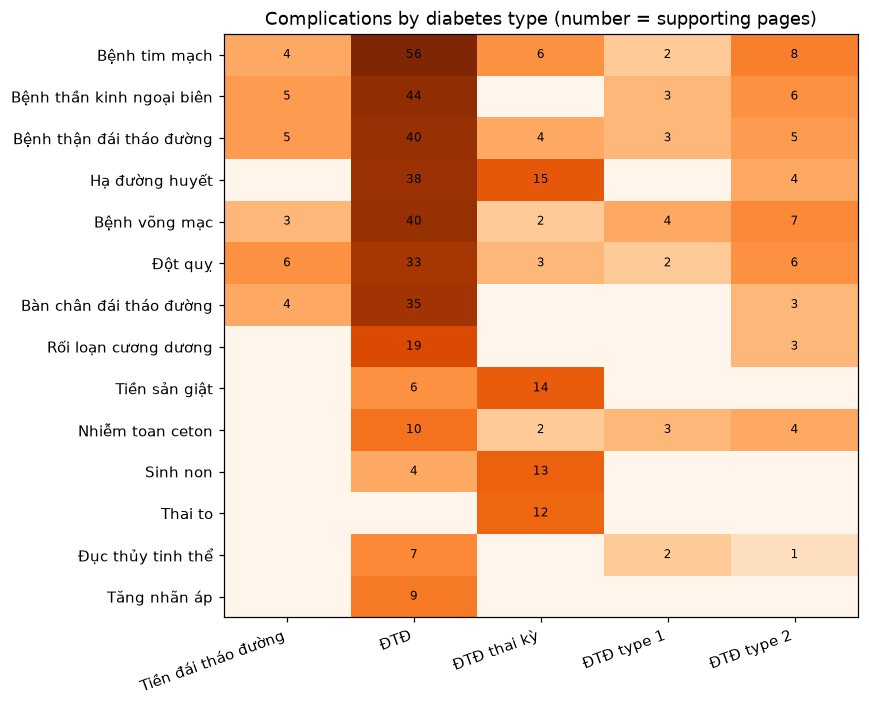

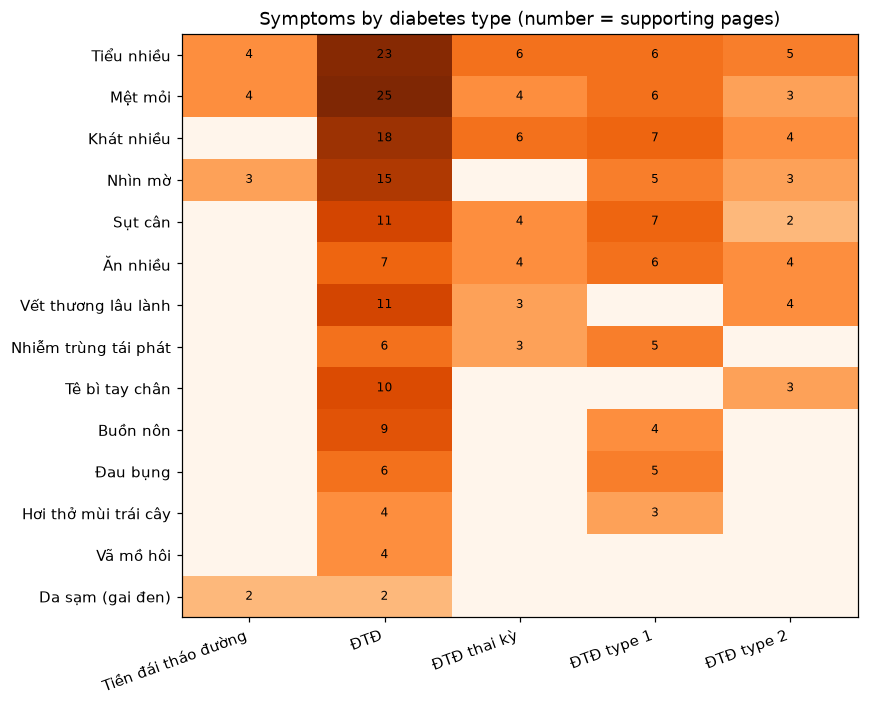

In [16]:
def heat(rel, title, top=14):
    sub = tri[tri.relation == rel].pivot_table(index="object", columns="subject", values="support", fill_value=0)
    sub = sub.loc[sub.sum(axis=1).sort_values(ascending=False).index[:top]]
    sub.columns = [c.replace("Đái tháo đường", "ĐTĐ") for c in sub.columns]
    plt.figure(figsize=(8, 0.38 * len(sub) + 1.2))
    plt.imshow(np.log1p(sub.values), cmap="Oranges", aspect="auto")
    plt.xticks(range(sub.shape[1]), sub.columns, rotation=20, ha="right"); plt.yticks(range(len(sub)), sub.index)
    for i in range(sub.shape[0]):
        for j in range(sub.shape[1]):
            if sub.values[i, j]: plt.text(j, i, int(sub.values[i, j]), ha="center", va="center", fontsize=8)
    plt.title(title + " (number = supporting pages)"); plt.tight_layout(); plt.show()

heat("HAS_COMPLICATION", "Complications by diabetes type")
heat("HAS_SYMPTOM", "Symptoms by diabetes type")

## 5. Storing the graph in Neo4j

### Why a graph database

The NetworkX graph lives in a Python process's memory: it vanishes when the process ends and every program must rebuild it from CSV. Fine for 7 facts; a real system needs durable knowledge shared by a notebook, a chatbot and a web page, answered quickly.

An ordinary SQL table of three columns could hold the triples, but graph questions are questions about **paths**, and in SQL each step along a path is another self-join: queries grow long, hard to read and slower with table size. A graph database stores each node with direct links to its neighbours, so following an arrow is a jump, not a search. **Neo4j** is the most widely used one and its language **Cypher** describes paths almost as a drawing.

### 5.1 Data model

```
(:Entity:Symptom {name})                 every vocabulary entity: label Entity + its type
(:Entity:Test {name, threshold})
(:DiabetesType)-[:HAS_SYMPTOM {support, source, example_urls}]->(:Symptom)
(:Article {url, title, page_type, date})-[:ABOUT]->(:DiabetesType)
(:Article)-[:MENTIONS]->(:Entity)
```

Three decisions:

- **Two labels per entity.** The type label (`Symptom`) lets us ask for "all symptoms"; the shared `Entity` label carries one uniqueness rule, so there can never be two "Metformin" nodes, and allows "everything connected to Metformin" without knowing neighbours' types.
- **Evidence lives on the relationship.** `support` and `example_urls` are relationship properties, so one query returns the answer, how well documented it is, and which articles say it. Stored elsewhere, each answer would need a second lookup.
- **Articles are nodes.** All 1,096 are `Article` nodes linked to the entities they mention and the type they are about. That keeps the path from clean facts back to the original text, which answers "where does this come from?", essential in medicine where an unverifiable answer should not be trusted.

### 5.2 Loading (`kg/load.py`)

```cypher
CREATE CONSTRAINT entity_name FOR (e:Entity) REQUIRE e.name IS UNIQUE;

UNWIND $rows AS r
MERGE (e:Entity {name: r.name}) SET e:Symptom;

UNWIND $rows AS r
MATCH (h:Entity {name: r.subject}), (t:Entity {name: r.object})
MERGE (h)-[x:HAS_SYMPTOM]->(t) SET x.support = r.support;
```

- **MERGE, not CREATE.** CREATE always adds; MERGE finds first and creates only if missing, so the loader can run repeatedly without duplicating facts.
- **UNWIND sends a batch per request.** Each round trip has a fixed cost; 10,000 mention links one by one would be 10,000 trips, while UNWIND ships the list once and the database loops. The whole load takes seconds.
- **The uniqueness constraint doubles as an index** on `name`, so "find the node called Metformin" jumps straight to it.
- **Relation types are in the query text**, because Cypher cannot take a relationship type as a parameter; the loader builds one query per relation type.

The next cell connects and counts what the database holds.

In [17]:
from neo4j import GraphDatabase
driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "diabetes123"))
driver.verify_connectivity()

def cy(query, **params):
    # run a Cypher query and return a DataFrame
    with driver.session() as s:
        return pd.DataFrame(s.run(query, **params).data())

nodes = cy("MATCH (n) UNWIND labels(n) AS l WITH l WHERE l <> 'Entity' RETURN l AS label, count(*) AS n ORDER BY n DESC")
rels = cy("MATCH ()-[r]->() RETURN type(r) AS relation, count(*) AS n ORDER BY n DESC")
display(nodes.T); display(rels.T)

,0,1,2,3,4,5,6,7,8,9,10
label,Article,Drug,Complication,Symptom,RiskFactor,Food,Test,DrugClass,Organ,Lifestyle,DiabetesType
n,1096,22,18,16,16,16,10,9,9,6,5


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
relation,MENTIONS,ABOUT,HAS_COMPLICATION,TREATED_BY,HAS_SYMPTOM,HAS_RISK_FACTOR,RECOMMENDS_FOOD,DIAGNOSED_BY,AVOIDS_FOOD,BELONGS_TO_CLASS,MANAGED_BY,AFFECTS_ORGAN,HAS_SIDE_EFFECT,SUBTYPE_OF
n,10083,1096,52,46,45,42,35,30,26,22,19,12,6,4


### 5.3 The shape of the graph

Neo4j can describe its own schema: which node types are linked by which relations, and how many times. The figure draws it, a circle per type and an arrow per kind of fact with its count.

It is the best summary of what the graph **can answer**, because each arrow is a kind of question. DiabetesType → Test answers "how is it diagnosed?"; Complication → Organ lets a path continue to the organ. There is no Food → Complication arrow, so "which food protects the kidneys?" is unanswerable, not because the articles are silent but because that fact type was never extracted.

The layout also shows the structure: diabetes types on the left, what the articles say about them in the middle, and the hand-added classifications (drug classes, organs) on the right.

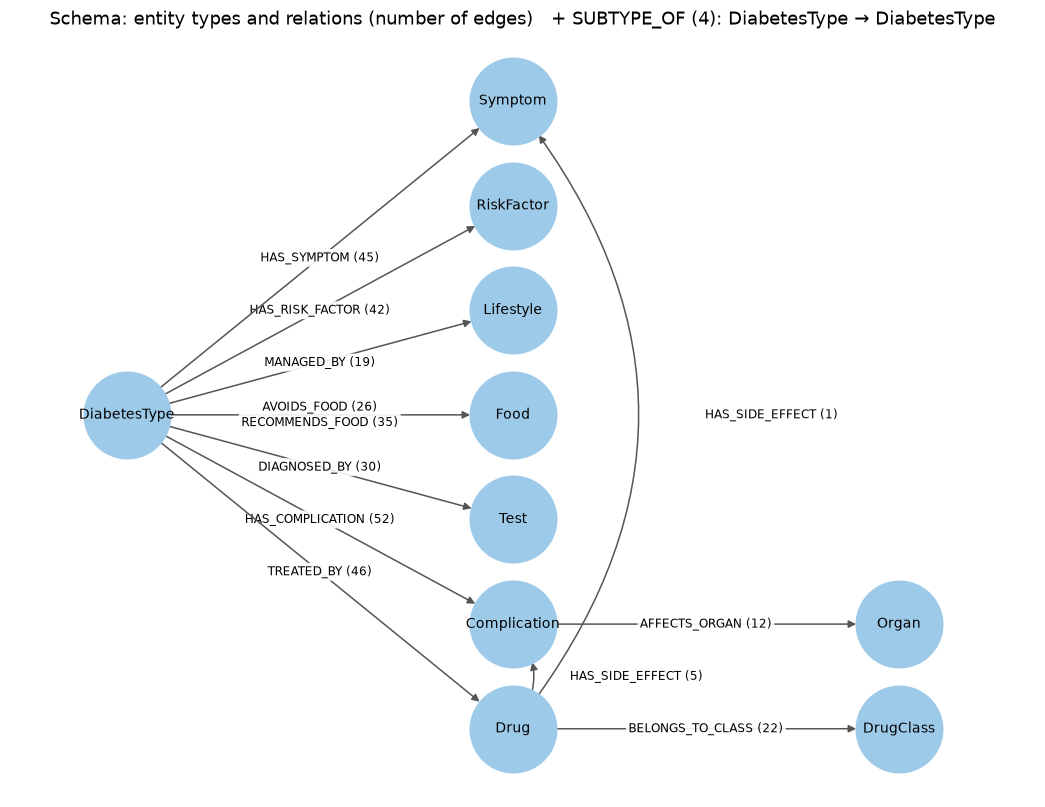

In [18]:
meta = cy('''
MATCH (a)-[r]->(b)
WHERE NOT a:Article
WITH [l IN labels(a) WHERE l <> 'Entity'][0] AS src, type(r) AS rel, [l IN labels(b) WHERE l <> 'Entity'][0] AS dst, count(*) AS n
RETURN src, rel, dst, n''')
# layered layout: diabetes types → what they point to → curated classifications
Y = 1.4   # vertical spacing
pos = {"DiabetesType": (0, 3 * Y), "Symptom": (4, 6 * Y), "RiskFactor": (4, 5 * Y), "Lifestyle": (4, 4 * Y),
       "Food": (4, 3 * Y), "Test": (4, 2 * Y), "Complication": (4, 1 * Y), "Drug": (4, 0),
       "Organ": (8, 1 * Y), "DrugClass": (8, 0)}
# several relation types between the same pair of types (e.g. RECOMMENDS_FOOD and AVOIDS_FOOD) share one arrow
pairs = defaultdict(list)
for r in meta.itertuples():
    if r.src != r.dst:
        pairs[(r.src, r.dst)].append(f"{r.rel} ({r.n})")
fig, ax = plt.subplots(figsize=(12, 9))
for (src, dst), labels in pairs.items():
    curved = src == "Drug" and dst in ("Symptom", "Complication")   # side effects run inside the middle column
    (x0, y0), (x1, y1) = pos[src], pos[dst]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="#555", lw=1, shrinkA=28, shrinkB=28,
                                connectionstyle="arc3,rad=0.4" if curved else "arc3"))
    if curved:   # the arc bulges to the right of the column, where there is free space
        lx, ly = x0 + 0.2 * (y1 - y0) + 1.0, (y0 + y1) / 2
    else:
        lx, ly = (x0 + x1) / 2, (y0 + y1) / 2
    ax.text(lx, ly, "\n".join(labels), fontsize=8, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
for name, (x, y) in pos.items():
    ax.scatter(x, y, s=3200, color="#9ecae9", zorder=3)
    ax.text(x, y, name, ha="center", va="center", fontsize=9, zorder=4)
ax.set_xlim(-1.2, 9.4); ax.set_ylim(-0.9, 6 * Y + 0.9); ax.axis("off")
ax.set_title("Schema: entity types and relations (number of edges)   + SUBTYPE_OF (4): DiabetesType → DiabetesType")
plt.show()

## 6. Asking questions with Cypher

### Reading a query

Cypher draws a path: round brackets for nodes, square brackets inside an arrow for relationships.

```cypher
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_SYMPTOM]->(s:Symptom)
RETURN s.name, r.support
```

Left to right: *find a DiabetesType named "type 2", follow outgoing HAS_SYMPTOM arrows to Symptom nodes, return the symptom name and the arrow's support.* `t`, `r`, `s` are names for the parts, reused in `RETURN`.

Neo4j answers by using the name index to land on the "type 2" node and looking only at the arrows attached to it, never at the rest of the database. The cost depends on how many arrows are followed, not on the database size, which is why graph queries stay fast as the graph grows.

All queries below are also in `kg/queries.cypher` for Neo4j Browser (http://localhost:7474), which draws the results as a graph.

### 6.1 One hop: everything connected to Metformin

In [19]:
cy('''
MATCH (e:Entity {name: 'Metformin'})-[r]-(n:Entity)
RETURN startNode(r).name AS subject, type(r) AS relation, endNode(r).name AS object, r.support AS support, r.source AS source
ORDER BY support DESC''')

,subject,relation,object,support,source
0,Đái tháo đường,TREATED_BY,Metformin,37,vinmec
1,Đái tháo đường type 2,TREATED_BY,Metformin,11,vinmec
2,Tiền đái tháo đường,TREATED_BY,Metformin,8,vinmec
3,Metformin,HAS_SIDE_EFFECT,Hạ đường huyết,5,vinmec
4,Metformin,BELONGS_TO_CLASS,Biguanide,0,curated


`-[r]-` has no arrowhead: an arrow in either direction. That is why both kinds of fact appear: those pointing into Metformin (type 2 *is treated by* Metformin) and the one leaving it (*belongs to* Biguanide).

Look at `support`: "diabetes is treated with Metformin" is stated by 37 articles, the side effect hypoglycaemia by 5, and the drug class has support 0 because it was added by hand (`source = curated`). Seeing support beside each fact lets a reader judge how solid it is.

### 6.2 Two hops: which organs can type 2 damage?

This is the Part 1 question on the real graph: type 2 → `HAS_COMPLICATION` → complication → `AFFECTS_ORGAN` → organ. No article states "type 2 damages the eye". The answer exists because an extracted fact (type 2 causes retinopathy) and a hand-added one (retinopathy affects the eye) meet at the complication node. `collect()` gathers all complications leading to one organ so each organ appears once with its reasons.

In [20]:
cy('''
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(c)-[:AFFECTS_ORGAN]->(o:Organ)
RETURN o.name AS organ, collect(c.name) AS via_complications, sum(r.support) AS evidence
ORDER BY evidence DESC''')

,organ,via_complications,evidence
0,Thần kinh,"[Rối loạn cương dương, Bệnh thần kinh ngoại biên]",9
1,Mắt,"[Đục thủy tinh thể, Bệnh võng mạc]",8
2,Tim mạch,[Bệnh tim mạch],8
3,Não,[Đột quỵ],6
4,Thận,[Bệnh thận đái tháo đường],5
5,Bàn chân,[Bàn chân đái tháo đường],3
6,Dạ dày,[Liệt dạ dày],1


### 6.3 Type 1 versus type 2 symptoms

For each symptom of the two types we collect which type it belongs to: both means shared, one means specific in Vinmec's articles.

The six classic symptoms (thirst, frequent urination, hunger, weight loss, fatigue, blurred vision) are shared, correctly: they come from high blood sugar, whatever the cause. The type 1-only ones, nausea, abdominal pain and fruity breath, are signs of ketoacidosis, the acid build-up when insulin is nearly absent, typical when type 1 is first found. (Recurrent infections also appear only for type 1; that is a general sign of high blood sugar which the type 2 pages just did not list under a symptom heading.) The type 2-only ones, slow-healing wounds and numb hands and feet, develop after years of mildly raised sugar, matching type 2's slow course. The graph reproduces a real clinical difference without being told.

In [21]:
cy('''
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom)
WHERE t.name IN ['Đái tháo đường type 1', 'Đái tháo đường type 2']
WITH s, collect(t.name) AS types, collect(r.support) AS sup
RETURN s.name AS symptom, CASE size(types) WHEN 2 THEN 'both' ELSE types[0] END AS found_in, sup AS support
ORDER BY found_in, symptom''')

,symptom,found_in,support
0,Khát nhiều,both,"[7, 4]"
1,Mệt mỏi,both,"[6, 3]"
2,Nhìn mờ,both,"[5, 3]"
3,Sụt cân,both,"[7, 2]"
4,Tiểu nhiều,both,"[6, 5]"
5,Ăn nhiều,both,"[6, 4]"
6,Buồn nôn,Đái tháo đường type 1,[4]
7,Hơi thở mùi trái cây,Đái tháo đường type 1,[3]
8,Nhiễm trùng tái phát,Đái tháo đường type 1,[5]
9,Đau bụng,Đái tháo đường type 1,[5]


### 6.4 A symptom checker

Given symptoms, which diabetes types do they point to? The query finds symptom facts for the given symptoms, groups by type, and ranks types by **how many of the given symptoms they have**, breaking ties by the summed support, i.e. which type the articles tie more strongly to these symptoms.

For {thirst, frequent urination, weight loss, blurred vision}, general diabetes, type 1 and type 2 all match four, with general diabetes first because most articles are general (3.4); gestational diabetes matches three.

This shows the use and the limit. The graph says which types the literature **associates** with these symptoms, and how strongly. It cannot say which diabetes a person has: the classic symptoms are common to all types and diagnosis needs blood tests, which is the next query. It retrieves information; it does not diagnose.

In [22]:
cy('''
WITH $input AS input
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom) WHERE s.name IN input
RETURN t.name AS type, count(s) AS matched, collect(s.name) AS symptoms, sum(r.support) AS evidence
ORDER BY matched DESC, evidence DESC''', input=["Khát nhiều", "Tiểu nhiều", "Sụt cân", "Nhìn mờ"])

,type,matched,symptoms,evidence
0,Đái tháo đường,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",67
1,Đái tháo đường type 1,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",25
2,Đái tháo đường type 2,4,"[Khát nhiều, Nhìn mờ, Sụt cân, Tiểu nhiều]",14
3,Đái tháo đường thai kỳ,3,"[Khát nhiều, Sụt cân, Tiểu nhiều]",16
4,Tiền đái tháo đường,2,"[Nhìn mờ, Tiểu nhiều]",7


### 6.5 A chain: from a risk factor to an organ

A three-step path: risk factor ← type → complication → organ. Each result row is a complete explanation in plain words: *obesity is a risk factor for type 2; type 2 can cause diabetic kidney disease; that disease damages the kidney.*

This chained explanation is what a graph gives and a document list does not. Each step is a separate fact, maybe from different articles, joined because they share a node.

In [23]:
cy('''
MATCH p = (rf:RiskFactor {name: 'Thừa cân, béo phì'})<-[:HAS_RISK_FACTOR]-(t:DiabetesType)
          -[:HAS_COMPLICATION]->(c:Complication)-[:AFFECTS_ORGAN]->(o:Organ {name: 'Thận'})
RETURN [n IN nodes(p) | n.name] AS path''')

,path
0,"[Thừa cân, béo phì, Tiền đái tháo đường, Bệnh thận đái tháo đường, Thận]"
1,"[Thừa cân, béo phì, Đái tháo đường type 2, Bệnh thận đái tháo đường, Thận]"
2,"[Thừa cân, béo phì, Đái tháo đường, Bệnh thận đái tháo đường, Thận]"
3,"[Thừa cân, béo phì, Đái tháo đường thai kỳ, Bệnh thận đái tháo đường, Thận]"


### 6.6 Diagnosis: which tests and what values?

This combines both kinds of knowledge. "Diabetes is diagnosed by HbA1c" was extracted from articles; the threshold "≥ 6.5 %" sits on the test node and was added by hand from the official guideline. Together they answer "how is diabetes diagnosed?" with numbers. The `evidence` column shows HbA1c and the glucose tolerance test as the tests articles mention most.

In [24]:
cy('''
MATCH (t:DiabetesType)-[r:DIAGNOSED_BY]->(x:Test)
RETURN x.name AS test, x.threshold AS threshold, collect(t.name) AS used_for, sum(r.support) AS evidence
ORDER BY evidence DESC''')

,test,threshold,used_for,evidence
0,HbA1c,≥ 6.5%,"[Đái tháo đường thai kỳ, Đái tháo đường type 1, Tiền đái tháo đường, Đái tháo đường, Đái tháo đường type 2]",67
1,Nghiệm pháp dung nạp glucose (OGTT),2 giờ ≥ 11.1 mmol/L (200 mg/dL),"[Đái tháo đường, Đái tháo đường type 1, Đái tháo đường thai kỳ, Tiền đái tháo đường, Đái tháo đường type 2]",59
2,Đường huyết lúc đói,≥ 7.0 mmol/L (126 mg/dL),"[Đái tháo đường type 1, Đái tháo đường, Tiền đái tháo đường, Đái tháo đường thai kỳ, Đái tháo đường type 2]",51
3,Xét nghiệm nước tiểu,NaN,"[Đái tháo đường, Đái tháo đường type 1, Đái tháo đường type 2]",14
4,Soi đáy mắt,NaN,"[Đái tháo đường type 2, Đái tháo đường, Đái tháo đường type 1]",11
5,Đường huyết ngẫu nhiên,≥ 11.1 mmol/L kèm triệu chứng,"[Đái tháo đường type 1, Đái tháo đường, Đái tháo đường type 2]",11
6,Máy đo đường huyết,NaN,[Đái tháo đường],10
7,Mỡ máu (lipid),NaN,"[Đái tháo đường, Đái tháo đường type 2, Đái tháo đường type 1]",7
8,C-peptide,NaN,[Đái tháo đường],2
9,Kháng thể kháng đảo tụy,NaN,[Đái tháo đường type 1],1


### 6.7 Drugs by class, with side effects

Each drug is listed with its class (hand-added), the number of articles discussing it as a treatment, and side effects extracted from sentences (3.8). Insulin dominates (143 articles), then Metformin (37), in line with practice: Metformin is first-line for type 2, and insulin is essential for type 1 and advanced type 2.

Check insulin's side effects: *ketoacidosis* is listed, and it is wrong. Ketoacidosis comes from a **lack** of insulin, and the "thiếu" filter of 3.8 did not catch this phrasing. This is a genuine extraction error left in the graph and recorded in Part 10.

In [25]:
cy('''
MATCH (d:Drug)-[:BELONGS_TO_CLASS]->(c:DrugClass)
OPTIONAL MATCH (d)-[se:HAS_SIDE_EFFECT]->(e)
OPTIONAL MATCH (:DiabetesType {name: 'Đái tháo đường'})-[tr:TREATED_BY]->(d)
RETURN c.name AS class, d.name AS drug, coalesce(tr.support, 0) AS articles, collect(e.name) AS side_effects
ORDER BY class, articles DESC''')

,class,drug,articles,side_effects
0,Biguanide,Metformin,37,[Hạ đường huyết]
1,Meglitinide,Repaglinide,6,[]
2,Nhóm Insulin,Insulin,143,"[Nhiễm toan ceton, Hạ đường huyết, Buồn nôn, Loãng xương]"
3,Nhóm Insulin,Insulin glargine,13,[]
4,Nhóm Insulin,Insulin aspart,11,[]
5,Nhóm Insulin,Insulin lispro,9,[]
6,Nhóm Insulin,Insulin NPH,6,[]
7,Sulfonylurea,Glimepiride,9,[]
8,Sulfonylurea,Gliclazide,8,[]
9,Sulfonylurea,Glibenclamide,5,[]


The query uses `OPTIONAL MATCH` for side effects. A plain MATCH would drop any drug without a side-effect fact, since the whole pattern must match; OPTIONAL MATCH keeps the drug and leaves the list empty.

### 6.8 Diet in gestational diabetes

Foods discussed in diet sections of gestational diabetes articles, split into recommended and avoided (the split comes from the fixed food list of 3.7), with article counts. Sweets lead the avoided foods; green vegetables, eggs and whole grains lead the recommended ones, which fits the usual advice for pregnant women with diabetes.

In [26]:
cy('''
MATCH (:DiabetesType {name: 'Đái tháo đường thai kỳ'})-[r:RECOMMENDS_FOOD|AVOIDS_FOOD]->(f:Food)
RETURN type(r) AS advice, f.name AS food, r.support AS articles
ORDER BY advice, articles DESC''')

,advice,food,articles
0,AVOIDS_FOOD,"Đồ ngọt, bánh kẹo",14
1,AVOIDS_FOOD,Thịt chế biến sẵn,7
2,AVOIDS_FOOD,Nước ngọt có ga,7
3,AVOIDS_FOOD,Rượu bia,6
4,AVOIDS_FOOD,"Đồ chiên rán, mỡ động vật",6
5,AVOIDS_FOOD,Trái cây nhiều đường,4
6,AVOIDS_FOOD,"Cơm trắng, tinh bột tinh chế",2
7,RECOMMENDS_FOOD,Rau xanh,13
8,RECOMMENDS_FOOD,Trứng,12
9,RECOMMENDS_FOOD,Ngũ cốc nguyên hạt,10


### 6.9 Where does a fact come from?

Each fact stores up to five example URLs. For "type 2 can cause diabetic kidney disease" we unpack them and look up the `Article` nodes for titles. The result is a list of real Vinmec articles anyone can open and check.

This traceability is what makes a graph trustworthy on health topics. A language model can answer fluently and wrongly with no way to verify; here every answer points back to its source.

In [27]:
cy('''
MATCH (:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(:Complication {name: 'Bệnh thận đái tháo đường'})
UNWIND r.example_urls AS url
MATCH (a:Article {url: url})
RETURN a.title AS article, a.url AS url''')

,article,url
0,Bệnh tiểu đường type 2 có nguy hiểm không?,https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-co-nguy-hiem-khong-vi
1,"Bệnh tiểu đường type 2: Nguyên nhân, biến chứng và phòng bệnh",https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-nguyen-nhan-bien-chung-nguy-hiem-doi-tuong-de-mac-nhat-vi
2,Các biến chứng nguy hiểm của bệnh đái tháo đường type 2,https://www.vinmec.com/vie/bai-viet/cac-bien-chung-nguy-hiem-cua-benh-dai-thao-duong-type-2-vi
3,Cách tự nhiên điều trị bệnh tiểu đường type 2 với những thực phẩm hàng ngày,https://www.vinmec.com/vie/bai-viet/cach-tu-nhien-dieu-tri-benh-tieu-duong-type-2-voi-nhung-thuc-pham-hang-ngay-vi
4,Triệu chứng sớm của đái tháo đường type 2,https://www.vinmec.com/vie/bai-viet/dau-hieu-som-cua-tieu-duong-type-2-vi


### 6.10 Which complications are written about together?

The `MENTIONS` links (article → every entity it mentions) give a looser signal: which topics share articles. The query counts, for each complication pair, the articles mentioning both.

This is not a medical fact (sharing an article does not imply causation) but it shows how Vinmec writes about diabetes. Cardiovascular disease and hypoglycaemia pair most often simply because each appears in a large share of all articles. That is the general weakness of raw co-occurrence: common topics always pair first. Finding *unusually* frequent pairs would mean comparing counts with what each topic's own frequency predicts.

In [28]:
cy('''
MATCH (a:Article)-[:MENTIONS]->(c1:Complication), (a)-[:MENTIONS]->(c2:Complication)
WHERE c1.name < c2.name
RETURN c1.name AS complication_1, c2.name AS complication_2, count(a) AS articles_together
ORDER BY articles_together DESC LIMIT 10''')

,complication_1,complication_2,articles_together
0,Bệnh tim mạch,Hạ đường huyết,170
1,Bệnh thận đái tháo đường,Bệnh tim mạch,163
2,Bệnh tim mạch,Đột quỵ,139
3,Bệnh thận đái tháo đường,Hạ đường huyết,116
4,Bệnh thần kinh ngoại biên,Bệnh tim mạch,110
5,Bệnh thận đái tháo đường,Bệnh võng mạc,107
6,Bệnh thần kinh ngoại biên,Bệnh thận đái tháo đường,100
7,Bệnh tim mạch,Bệnh võng mạc,98
8,Bệnh thận đái tháo đường,Đột quỵ,95
9,Bệnh thần kinh ngoại biên,Bệnh võng mạc,84


## 7. Graph retrieval: `graph_facts(entity, hops)`

In a full question-answering system (the lecture's KG + RAG design) a language model writes the answer and the graph supplies a small set of reliable facts to base it on. `kg/retriever.py` does that:

1. find the node named in the question;
2. collect the facts within one hop (or two);
3. turn each into a short sentence, "subject RELATION object.";
4. sort by support so the best-documented facts come first, and return at most 30.

The limit matters: two hops from a common node can reach hundreds of facts, far more than a language model's prompt should carry. Ranking by support makes the cut keep the most reliable ones.

In [29]:
from retriever import graph_facts
print("1 hop from 'Hạ đường huyết':")
for f in graph_facts(driver, "Hạ đường huyết", hops=1): print("  ", f)

two = graph_facts(driver, "Hạ đường huyết", hops=2, limit=1000)
print(f"\n2 hops: {len(two)} facts (only the first 30 would be returned) — e.g.")
for f in two[5:12]: print("  ", f)

1 hop from 'Hạ đường huyết':
   Đái tháo đường HAS_COMPLICATION Hạ đường huyết.
   Insulin HAS_SIDE_EFFECT Hạ đường huyết.
   Đái tháo đường thai kỳ HAS_COMPLICATION Hạ đường huyết.
   Metformin HAS_SIDE_EFFECT Hạ đường huyết.
   Đái tháo đường type 2 HAS_COMPLICATION Hạ đường huyết.

2 hops: 230 facts (only the first 30 would be returned) — e.g.
   Đái tháo đường TREATED_BY Insulin.
   Đái tháo đường MANAGED_BY Tập thể dục đều đặn.
   Đái tháo đường MANAGED_BY Giảm cân.
   Đái tháo đường HAS_COMPLICATION Bệnh tim mạch.
   Đái tháo đường RECOMMENDS_FOOD Ngũ cốc nguyên hạt.
   Đái tháo đường AVOIDS_FOOD Rượu bia.
   Đái tháo đường AVOIDS_FOOD Đồ ngọt, bánh kẹo.


## 8. Drawing the graph and finding the important entities

Drawing and measuring use NetworkX rebuilt from the same CSV files that were loaded into Neo4j, so both hold identical facts.

### 8.1 The whole graph

Colour shows type; size shows the number of facts a node is in. The five diabetes types are large hubs at the centre because almost every extracted fact starts from one of them, with symptoms, complications, drugs, foods and tests around them. The hand-added facts form short chains at the edge: drug → class, complication → organ.

With 127 nodes and 339 edges the picture is dense but readable. The density is about 2 %: only that share of the possible links among 127 nodes exists. Each entity connects to a few others, never to everything, which is normal for real knowledge graphs.

127 nodes, 339 edges, density = 0.021


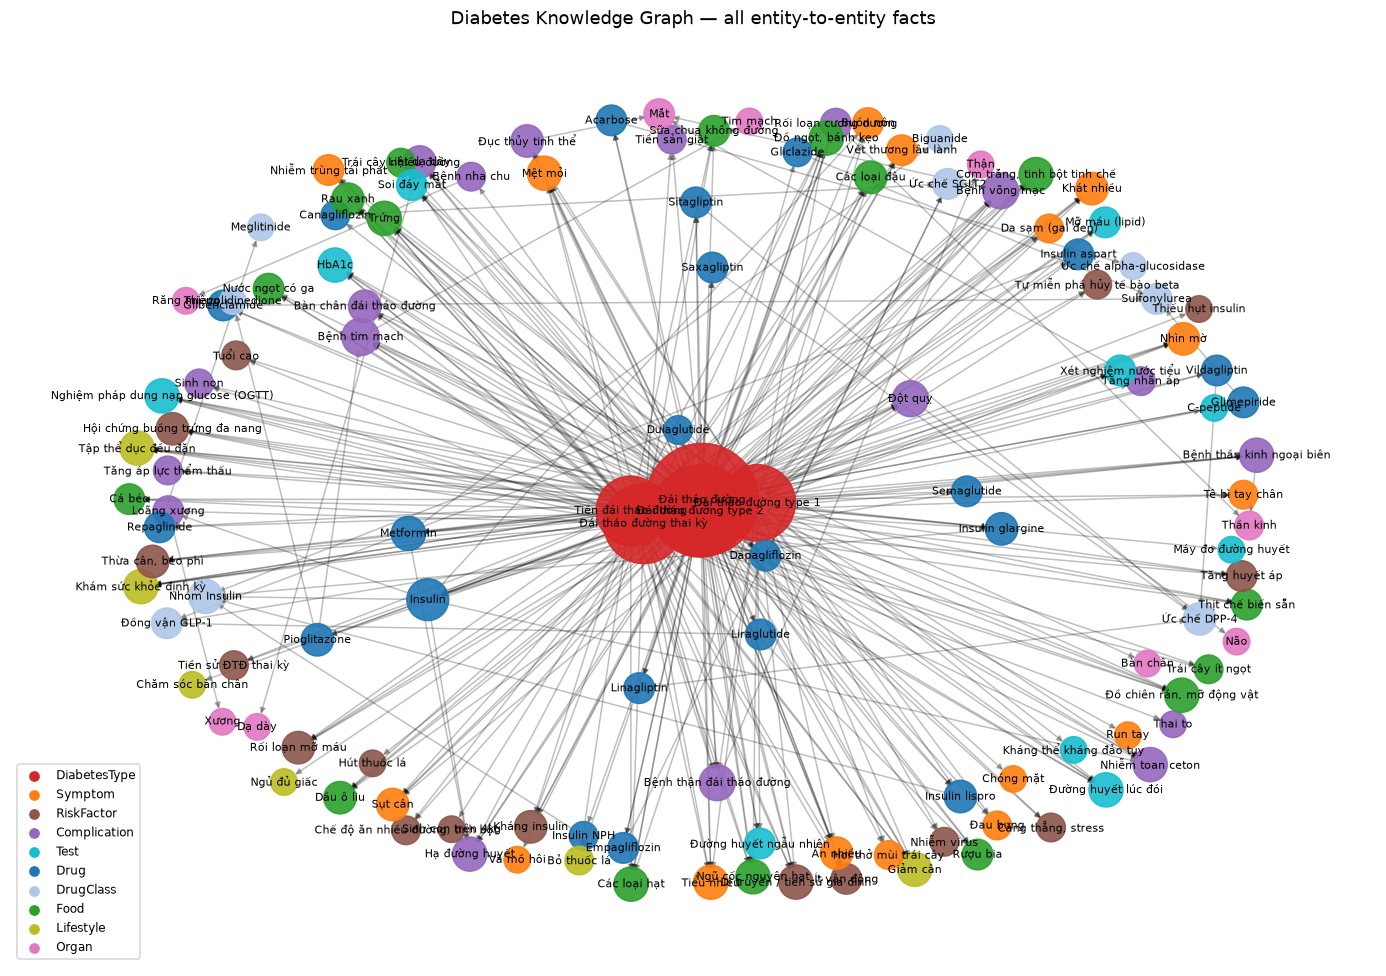

In [30]:
from visualize import build_graph, COLORS
%matplotlib inline
G = build_graph()
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, density = {nx.density(G):.3f}")

def draw(H, title, edge_labels=False, k=0.9, size=(16, 11)):
    plt.figure(figsize=size)
    pos = nx.spring_layout(H, k=k, seed=7)
    nx.draw_networkx_edges(H, pos, alpha=0.25, arrowsize=8)
    nx.draw_networkx_nodes(H, pos, node_color=[COLORS.get(H.nodes[n].get("type"), "#999") for n in H],
                           node_size=[250 + 50 * H.degree(n) for n in H], alpha=0.9)
    nx.draw_networkx_labels(H, pos, font_size=7)
    if edge_labels:
        nx.draw_networkx_edge_labels(H, pos, nx.get_edge_attributes(H, "relation"), font_size=6)
    for lab, c in COLORS.items(): plt.scatter([], [], c=c, label=lab)
    plt.legend(loc="lower left", fontsize=8); plt.title(title); plt.axis("off"); plt.show()

draw(G, "Diabetes Knowledge Graph — all entity-to-entity facts")

### 8.2 One part at a time

The full picture shows structure but not detail, so two focused views follow:

- **Gestational diabetes and its direct neighbours**, with relation names on the edges: its symptoms, pregnancy-specific complications, tests and foods, readable at a glance.
- **Type 2 treatment**: drugs, their classes and side effects. Drawing the class edges makes drug families cluster (several DPP-4 inhibitors around their class, several SGLT2 inhibitors around theirs), which is how clinicians group them.

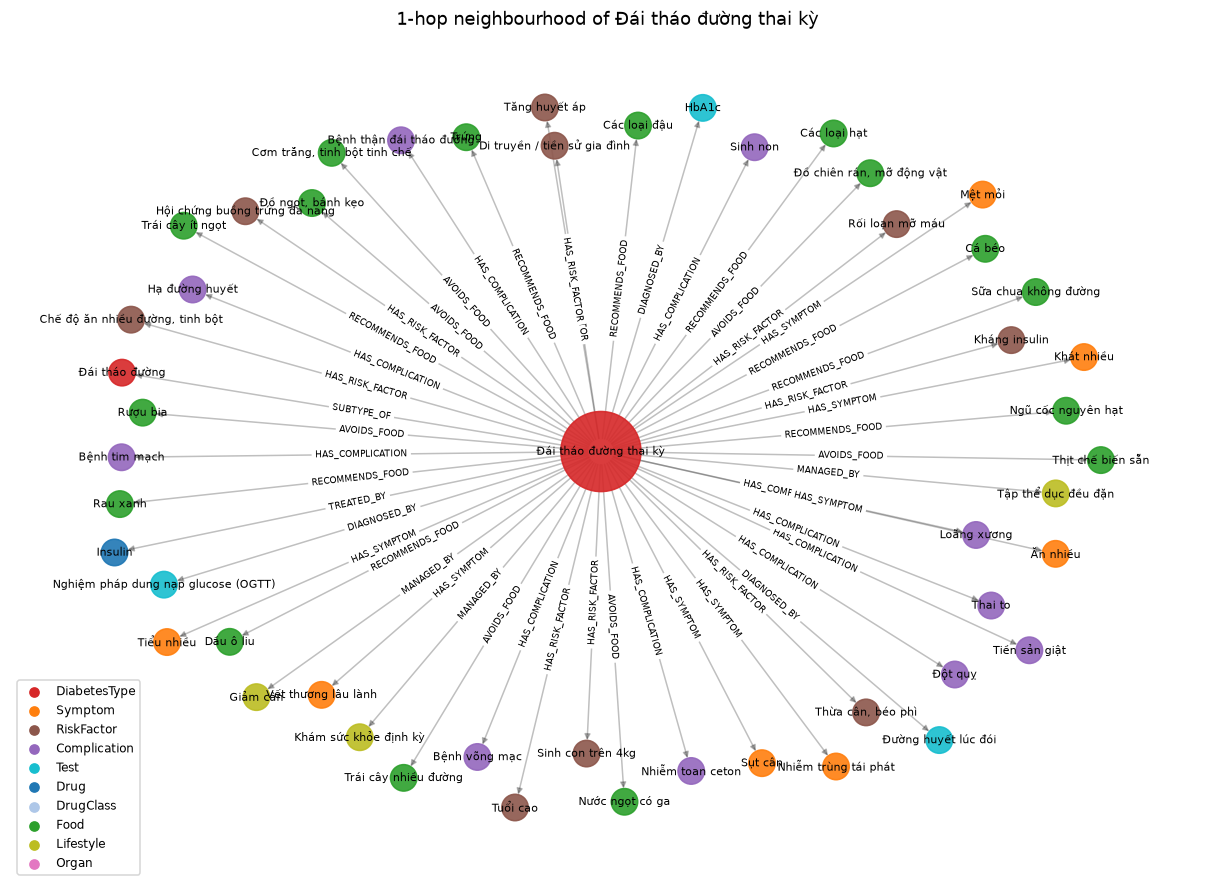

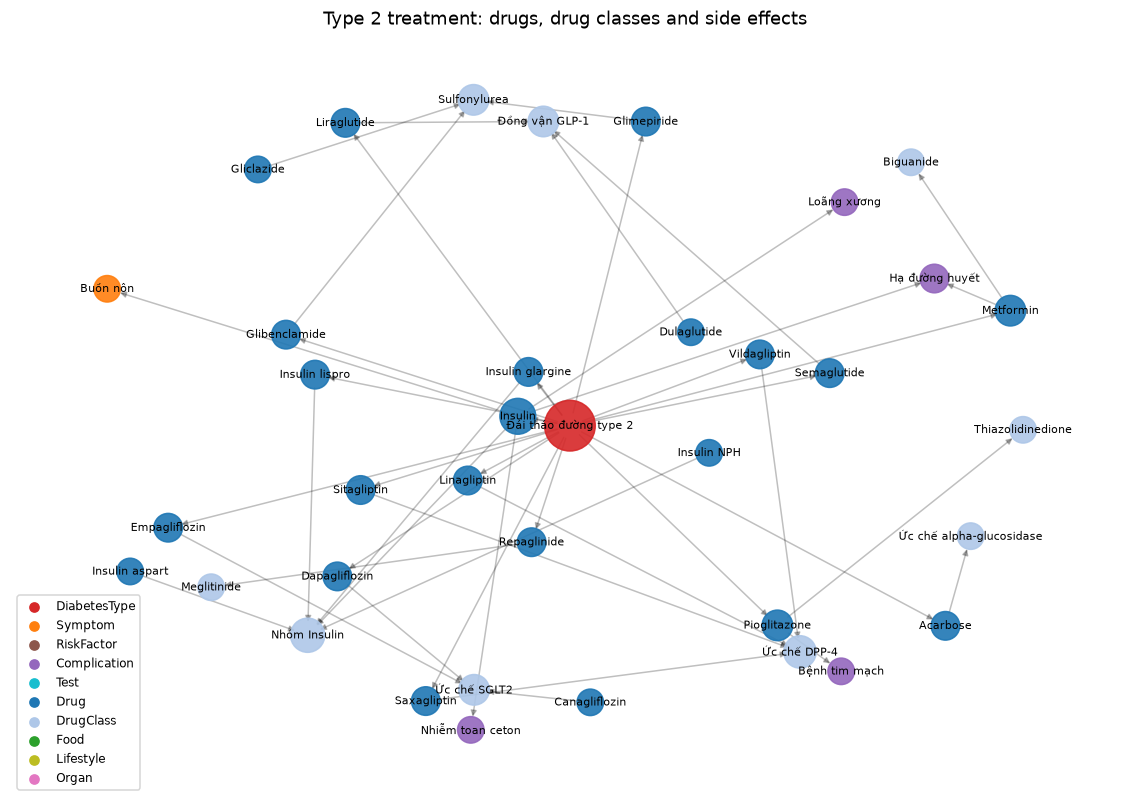

In [31]:
def one_hop(G, center):
    H = nx.DiGraph(); H.add_node(center, **G.nodes[center])
    for u, v, d in [*G.out_edges(center, data=True), *G.in_edges(center, data=True)]:
        H.add_node(u, **G.nodes[u]); H.add_node(v, **G.nodes[v]); H.add_edge(u, v, **d)
    return H

draw(one_hop(G, "Đái tháo đường thai kỳ"), "1-hop neighbourhood of Đái tháo đường thai kỳ", edge_labels=True, k=1.4, size=(14, 10))

drug_edges = [(u, v, d) for u, v, d in G.edges(data=True)
              if (u == "Đái tháo đường type 2" and d["relation"] == "TREATED_BY") or d["relation"] in ("BELONGS_TO_CLASS", "HAS_SIDE_EFFECT")]
D = nx.DiGraph()
for u, v, d in drug_edges:
    D.add_node(u, **G.nodes[u]); D.add_node(v, **G.nodes[v]); D.add_edge(u, v, **d)
draw(D, "Type 2 treatment: drugs, drug classes and side effects", k=0.8, size=(13, 9))

### 8.3 Which entities matter most?

"Important" has several meanings, and two standard measures disagree here, which is instructive about the graph itself.

**Degree** counts the arrows touching a node: how many facts involve this entity. It ignores where those arrows lead.

**PageRank** says a node matters if *important* nodes point to it. Picture a walker who follows a random outgoing arrow at each step and occasionally jumps to a random node; PageRank is the share of time spent on each node after a very long walk.

**What happens here.** All our arrows point *away* from the diabetes types (type → drug → class, type → complication → organ). A walker following them drifts to the ends of the chains, the drug classes and organs, which have no outgoing arrows, and waits there for a random jump. So directed PageRank ranks "Nhóm Insulin", "Ức chế DPP-4" and "Mắt" at the top. They are not what the articles are about; they are where paths end.

The direction itself was our design choice ("type 2 HAS_SYMPTOM thirst" could equally be "thirst SYMPTOM_OF type 2"). A score that flips when a relation is renamed does not measure what we want, so PageRank is also computed **ignoring direction**. Then a node is important if it is well connected to other well-connected nodes, and the ranking makes sense: diabetes types first, then insulin, cardiovascular disease, stroke, kidney disease, retinopathy and Metformin, the treatments and complications that hold the graph together.

A graph measure answers one specific question; check that it is yours.

Top by directed PageRank (dead ends of the chains):


,type,degree,PR directed,PR undirected
Nhóm Insulin,DrugClass,5,0.0290,0.0077
Ức chế DPP-4,DrugClass,4,0.0277,0.0067
Mắt,Organ,3,0.0226,0.0053
Đồng vận GLP-1,DrugClass,3,0.0222,0.0058
Ức chế SGLT2,DrugClass,3,0.0222,0.0058
Sulfonylurea,DrugClass,3,0.0222,0.0058
Thần kinh,Organ,2,0.0171,0.0039
Tim mạch,Organ,1,0.0142,0.0024


Top by undirected PageRank (central entities):


,type,degree,PR directed,PR undirected
Đái tháo đường,DiabetesType,104,0.0066,0.1456
Đái tháo đường type 2,DiabetesType,68,0.0062,0.0881
Đái tháo đường thai kỳ,DiabetesType,50,0.0062,0.0645
Đái tháo đường type 1,DiabetesType,45,0.0062,0.0572
Tiền đái tháo đường,DiabetesType,36,0.0062,0.0449
Insulin,Drug,10,0.0067,0.0133
Bệnh tim mạch,Complication,7,0.0094,0.0103
Đột quỵ,Complication,6,0.0067,0.0088
Bệnh thận đái tháo đường,Complication,6,0.0067,0.0088
Bệnh võng mạc,Complication,6,0.0067,0.0082


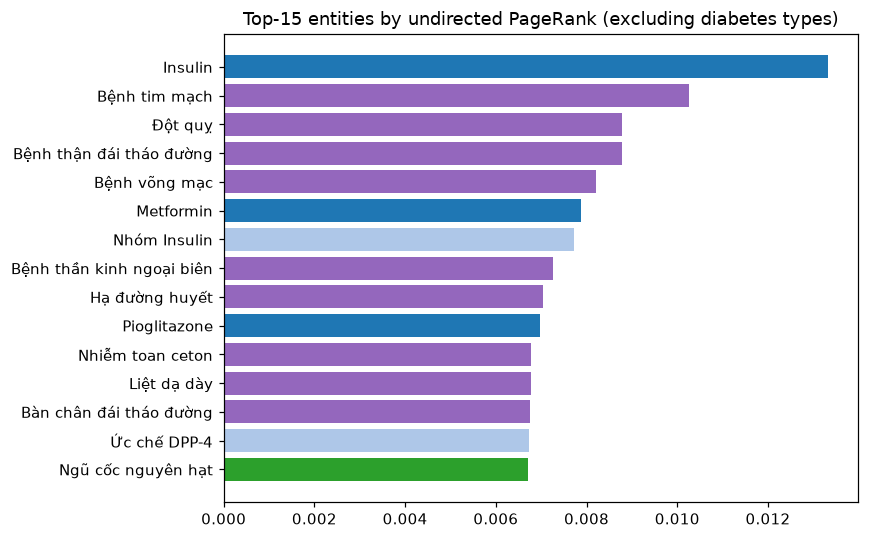

In [32]:
pr_dir = nx.pagerank(G, alpha=0.85)
pr_und = nx.pagerank(G.to_undirected(), alpha=0.85)
cent = pd.DataFrame({"type": nx.get_node_attributes(G, "type"), "degree": dict(G.degree()),
                     "PR directed": pr_dir, "PR undirected": pr_und})
fmt = {"PR directed": "{:.4f}", "PR undirected": "{:.4f}"}
print("Top by directed PageRank (dead ends of the chains):")
display(cent.sort_values("PR directed", ascending=False).head(8).style.format(fmt))
print("Top by undirected PageRank (central entities):")
display(cent.sort_values("PR undirected", ascending=False).head(12).style.format(fmt))

top = cent[cent.type != "DiabetesType"].sort_values("PR undirected", ascending=False).head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["PR undirected"], color=[COLORS[t] for t in top.type])
plt.title("Top-15 entities by undirected PageRank (excluding diabetes types)"); plt.tight_layout(); plt.show()

### 8.4 What Vinmec writes about most

A third view ignores facts and counts, per entity, the articles that mention it anywhere (the `MENTIONS` links). This is what the site **talks about**, different from how connected an entity is in the fact graph. An entity can appear in many articles in passing, say while blood sugar is explained, yet take part in few extracted facts. Comparing this chart with the PageRank one shows which topics are discussed often but rarely stated under a proper heading.

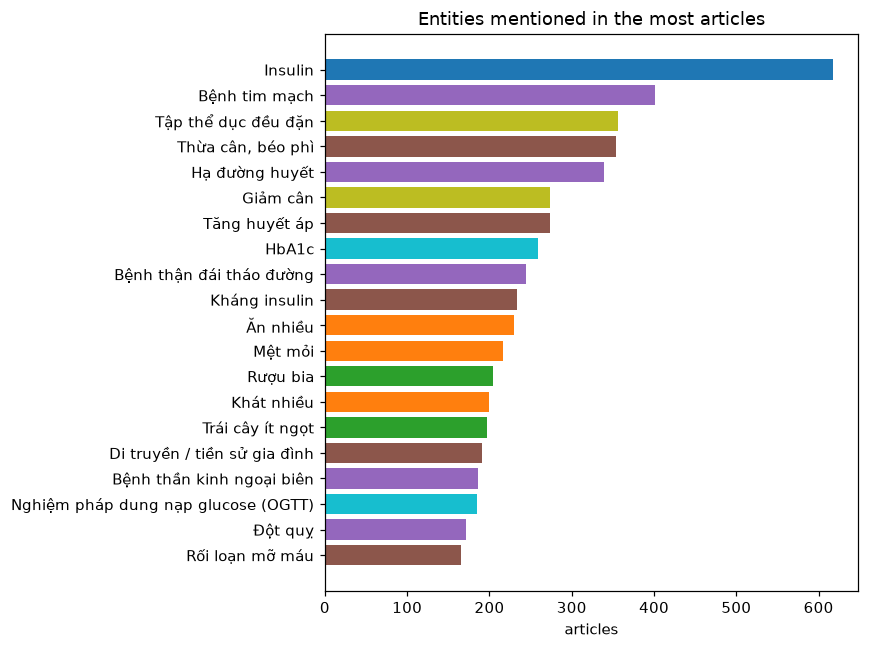

In [33]:
mc = cy('''
MATCH (a:Article)-[:MENTIONS]->(e:Entity)
RETURN [l IN labels(e) WHERE l <> 'Entity'][0] AS type, e.name AS entity, count(a) AS articles
ORDER BY articles DESC LIMIT 20''')[::-1]
plt.figure(figsize=(8, 6))
plt.barh(mc.entity, mc.articles, color=[COLORS.get(t, "#999") for t in mc.type])
plt.title("Entities mentioned in the most articles"); plt.xlabel("articles"); plt.tight_layout(); plt.show()

## 9. How good is the graph?

Every automatic extractor makes mistakes. What matters is how many and what kind; without measuring, no claim from the graph ("insulin causes X") can be trusted.

### Method

We measured **precision**: of the facts in the graph, what share is correct?

1. Draw 50 extracted facts at random with a fixed seed (rerunning `kg/evaluate.py` gives the same 50).
2. For each, show the article title and a sentence from a section the extractor actually used.
3. Judge each fact by reading **all** of its supporting articles, not just the sentence shown.

"Correct" means the Vinmec articles really state this fact for this diabetes type. It does not mean a physician checked it against current guidelines, a different and much costlier test.

Random, because hand-picked facts would unconsciously be easy ones and flatter the result. Fifty, because each judgement means reading several articles; 50 is enough to see the main error patterns and give a usable estimate.

### Result

**48 of 50 facts are correct (96 %).** Both errors share one cause: a fact about a *complication* was attached to diabetes itself.

| wrong fact | what the articles said |
|---|---|
| diabetes HAS_RISK_FACTOR high cholesterol | listed as a risk factor of *kidney* and *eye* complications ("Những ai dễ bị bệnh thận đái tháo đường?") |
| diabetes HAS_SYMPTOM abdominal pain | a symptom of *ketoacidosis* and of gut nerve damage |

With only 50 facts the true rate could be higher or lower; a different sample might have shown one error or four. The standard (Wilson) 95 % interval for 48 of 50 is about **87 % to 99 %**. Read "96 %" as "roughly nine in ten or better", not an exact figure.

The cell recomputes the number and the interval from `evaluation/manual_audit.csv`.

In [34]:
sample = pd.read_csv(ROOT / "evaluation" / "manual_audit.csv")
n, k = len(sample), int(sample.correct.sum())
z = 1.96; p = k / n
centre = (p + z*z/(2*n)) / (1 + z*z/n); half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
print(f"precision = {k}/{n} = {p:.2f}   likely range for the whole graph: {centre-half:.2f} to {centre+half:.2f}\n")
display(sample.groupby("relation").correct.agg(["count", "sum"]).rename(columns={"count": "sampled", "sum": "correct"}))
display(sample[sample.correct == 0][["subject", "relation", "object", "error_type"]])

precision = 48/50 = 0.96   likely range for the whole graph: 0.87 to 0.99



,sampled,correct
relation,,
AVOIDS_FOOD,7,7
DIAGNOSED_BY,6,6
HAS_COMPLICATION,7,7
HAS_RISK_FACTOR,11,10
HAS_SYMPTOM,7,6
MANAGED_BY,2,2
RECOMMENDS_FOOD,3,3
TREATED_BY,7,7


,subject,relation,object,error_type
3,Đái tháo đường,HAS_RISK_FACTOR,Rối loạn mỡ máu,risk factor of a complication attached to the disease
30,Đái tháo đường,HAS_SYMPTOM,Đau bụng,symptom of a complication (DKA / neuropathy) attached to the disease


### 9.1 Fixing the errors and what it cost

The two errors led to the stricter heading rule of 3.3: a symptom or risk factor section must be about diabetes itself. The graph went from 345 to 339 facts. The six removed facts:

| removed fact | removal right? |
|---|---|
| type 1 HAS_SYMPTOM numb hands and feet | ✅ neuropathy complication, not a type 1 symptom |
| type 2 HAS_SYMPTOM sweating | ✅ a hypoglycaemia symptom |
| prediabetes HAS_RISK_FACTOR older age | ❌ a true fact lost |
| prediabetes HAS_RISK_FACTOR high blood pressure | ❌ a true fact lost |
| diabetes HAS_RISK_FACTOR long-term corticosteroids | ❌ a true fact lost |
| type 2 HAS_RISK_FACTOR smoking | ❌ a true fact lost |

The four true facts each had one good page and one weak one. The stricter rule removed the weak page, support fell to 1, and the minimum of 2 removed the fact.

The two original errors stayed, with far less support (16 → 3 and 18 → 6 pages). The remaining pages do state them under genuine diabetes headings (e.g. "Nguyên nhân và yếu tố nguy cơ gây bệnh tiểu đường: … Rối loạn mỡ máu"), so by our definition they are now properly supported.

Every extractor faces this trade-off: strict rules give fewer wrong but also fewer true facts, loose rules the reverse, and no setting suits every use. That is why support stays on every fact rather than being used once as a filter. A health chatbot might use only facts with support ≥ 3, while someone exploring the data can see everything.

The cell counts how many extracted facts survive at each support threshold.

In [35]:
for th in [1, 2, 3, 5, 10]:
    cnt = cy("MATCH ()-[r]->() WHERE r.source = 'vinmec' AND r.support >= $t RETURN count(r) AS n", t=th).n[0]
    print(f"facts with support ≥ {th:2d}: {cnt}")

facts with support ≥  1: 301
facts with support ≥  2: 295
facts with support ≥  3: 252
facts with support ≥  5: 161
facts with support ≥ 10: 70


## 10. Limitations

Following the lecture's list of knowledge graph failure modes:

- **Missing entities.** The vocabulary is fixed at 106 entities in 320 spellings. Anything outside it is invisible however often articles discuss it: a newer insulin brand, a rarer complication, a folk remedy. Precision was measured, recall was not, so the amount missing is unknown.
- **Wrong relations.** About 4 % of sampled facts were wrong, mainly complication facts attached to the disease. Headings are a strong but imperfect signal.
- **Ambiguous aliases.** Whole-word matching stops matches inside longer words but not short aliases that are words in their own right: "táo" (fruit) also matches "táo bón" (constipation). The section rule makes it rare, not impossible.
- **Cause read as side effect.** "Insulin HAS_SIDE_EFFECT ketoacidosis" slipped through 3.8: ketoacidosis comes from a *lack* of insulin, phrased in a way the "thiếu / không đủ" check misses.
- **Coarse subjects.** The diabetes type comes only from the title, so many type 2 facts sit on the general node.
- **Fixed food advice.** Recommended vs avoided is a property of the food, so "fruit is fine in moderation" is lost.
- **Merged meanings.** Aliases deliberately merge near-synonyms ("tê bì", "dị cảm", "kiến bò" → numb hands and feet), sometimes merging what a doctor would separate.
- **One source, mixed ages.** Everything comes from one hospital's site, and a 2019 article weighs the same as a 2025 one. "Correct" means "stated by Vinmec", not "checked against current guidelines".
- **Curated facts.** Drug classes, organs and thresholds were added by hand. They are labelled `curated` but not learned from the articles.
- **Not medical advice.** The graph summarises public articles. The symptom checker shows associations in those articles; it diagnoses nobody.

In [36]:
driver.close()